<a href="https://colab.research.google.com/github/sushirito/MPLBM-UT/blob/master/SensorVsErrors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sensor Count: 10, Test MSE: 0.11871
Sensor Count: 100, Test MSE: 0.01603
Sensor Count: 1000, Test MSE: 0.00377
Sensor Count: 4000, Test MSE: 0.00284


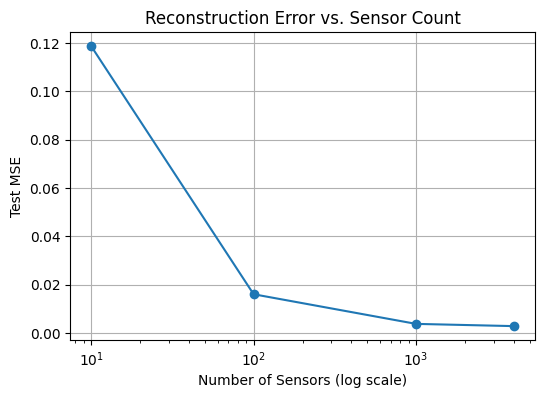

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

###############################################################################
# 1. Ground Truth Field Simulation
#    Create a smooth 64x64 Hg field with values in [0.1, 2] nM.
###############################################################################
grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

def ground_truth_field():
    # A smooth field defined by sinusoidal functions + noise
    raw = np.sin(3*np.pi*xx) * np.cos(4*np.pi*yy) + 0.5*np.sin(5*np.pi*xx*yy)
    # Normalize to [0,1]
    raw_norm = (raw - raw.min()) / (raw.max() - raw.min())
    # Scale to [0.1, 2.0] nM
    field = 0.1 + 1.9 * raw_norm
    # Add a bit of noise and clip
    noise = np.random.normal(0, 0.05, size=field.shape)
    field = np.clip(field + noise, 0.1, 2.0)
    return field

###############################################################################
# 2. Dataset Definition
#    For each sample, randomly select N sensor locations (from 4096 grid points)
#    and create a two-channel input:
#       - Channel 1: sensor measurements at sampled locations (0 elsewhere)
#       - Channel 2: binary mask indicating sensor locations
#    The target is the full Hg field.
###############################################################################
class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [ground_truth_field() for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]  # shape (64,64)
        total_points = grid_size * grid_size

        # Randomly select sensor_count indices from the grid (without replacement)
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)

        # Create mask and masked field arrays
        masked_field = np.zeros((grid_size, grid_size), dtype=np.float32)
        mask = np.zeros((grid_size, grid_size), dtype=np.float32)

        # Fill in sensor values and mask
        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0
        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)

        # Two-channel input: (2,64,64)
        inp = np.stack([masked_field, mask], axis=0)
        # Target full field: (1,64,64)
        target = field[np.newaxis, ...]
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(target, dtype=torch.float32)

###############################################################################
# 3. CNN Autoencoder Model
#    A simple CNN autoencoder that maps a 2-channel input to a 1-channel output.
###############################################################################
class CNNAutoencoder(nn.Module):
    def __init__(self):
        super(CNNAutoencoder, self).__init__()
        # Encoder: downsample the input to a latent representation
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),  # (B,32,64,64)
            nn.ReLU(),
            nn.MaxPool2d(2),                             # (B,32,32,32)
            nn.Conv2d(32, 64, kernel_size=3, padding=1), # (B,64,32,32)
            nn.ReLU(),
            nn.MaxPool2d(2),                             # (B,64,16,16)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),# (B,128,16,16)
            nn.ReLU(),
            nn.MaxPool2d(2)                              # (B,128,8,8)
        )
        # Decoder: upsample latent representation back to full field
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),  # (B,64,16,16)
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),   # (B,32,32,32)
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),    # (B,1,64,64)
            nn.Sigmoid()  # outputs in [0,1]
        )

    def forward(self, x):
        latent = self.encoder(x)
        output = self.decoder(latent)
        # Rescale the output from [0,1] to [0.1,2.0]
        output = 0.1 + 1.9 * output
        return output

###############################################################################
# 4. Training Routine and Evaluation Function
###############################################################################
def train_autoencoder(sensor_count, num_epochs=50, batch_size=32):
    # Create training and testing datasets (e.g., 400 training, 100 testing samples)
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = CNNAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    # Training loop
    model.train()
    for epoch in range(num_epochs):
        running_loss = 0.0
        for inp, target in train_loader:
            optimizer.zero_grad()
            output = model(inp)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inp.size(0)
        epoch_loss = running_loss / len(train_dataset)
        # Optionally, print training progress:
        # print(f"Sensor Count: {sensor_count}, Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

    # Evaluate on test set
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, target in test_loader:
            output = model(inp)
            loss = criterion(output, target)
            total_loss += loss.item() * inp.size(0)
    test_mse = total_loss / len(test_dataset)
    return test_mse, model

###############################################################################
# 5. Run Experiments for Different Sensor Counts and Plot Results
###############################################################################
sensor_counts = [10, 100, 1000, 4000]
errors = []

for sc in sensor_counts:
    mse, _ = train_autoencoder(sc, num_epochs=50, batch_size=32)
    errors.append(mse)
    print(f"Sensor Count: {sc}, Test MSE: {mse:.5f}")

plt.figure(figsize=(6,4))
plt.plot(sensor_counts, errors, marker='o')
plt.xscale('log')
plt.xlabel("Number of Sensors (log scale)")
plt.ylabel("Test MSE")
plt.title("Reconstruction Error vs. Sensor Count")
plt.grid(True)
plt.show()


Scenario 1, Sensors=1, MSE=0.2068
Scenario 1, Sensors=10, MSE=0.1524
Scenario 1, Sensors=100, MSE=0.0178
Scenario 1, Sensors=1000, MSE=0.0018
Scenario 2, Sensors=1, MSE=0.2159
Scenario 2, Sensors=10, MSE=0.1624
Scenario 2, Sensors=100, MSE=0.0303
Scenario 2, Sensors=1000, MSE=0.0112
Scenario 3, Sensors=1, MSE=0.2143
Scenario 3, Sensors=10, MSE=0.1633
Scenario 3, Sensors=100, MSE=0.0165
Scenario 3, Sensors=1000, MSE=0.0016
Scenario 4, Sensors=1, MSE=0.2016
Scenario 4, Sensors=10, MSE=0.1475
Scenario 4, Sensors=100, MSE=0.0192
Scenario 4, Sensors=1000, MSE=0.0012


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Global grid parameters
grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

###############################################################################
# 1. Field Scenarios (Physical Models for Hg Concentrations)
###############################################################################
def field_scenario_1():
    # Scenario 1: Low Noise (Smooth Field)
    raw = np.sin(3*np.pi*xx) * np.cos(4*np.pi*yy)
    raw_norm = (raw - raw.min()) / (raw.max() - raw.min())
    field = 0.1 + 1.9 * raw_norm
    noise = np.random.normal(0, 0.01, size=field.shape)
    return np.clip(field + noise, 0.1, 2.0)

def field_scenario_2():
    # Scenario 2: High Noise / Turbulence
    raw = np.sin(3*np.pi*xx) * np.cos(4*np.pi*yy)
    raw_norm = (raw - raw.min()) / (raw.max() - raw.min())
    field = 0.1 + 1.9 * raw_norm
    noise = np.random.normal(0, 0.1, size=field.shape)
    return np.clip(field + noise, 0.1, 2.0)

def field_scenario_3():
    # Scenario 3: Localized Hotspots
    raw = np.sin(3*np.pi*xx) * np.cos(4*np.pi*yy)
    raw_norm = (raw - raw.min()) / (raw.max() - raw.min())
    field = 0.1 + 1.9 * raw_norm
    hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
    for (cx, cy) in hotspot_centers:
        dist_sq = (xx - cx)**2 + (yy - cy)**2
        hotspot = np.exp(-dist_sq / 0.005)  # sharp, localized
        field += 0.5 * hotspot
    field = np.clip(field, 0.1, 2.0)
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0.1, 2.0)

def field_scenario_4():
    # Scenario 4: Spatial Gradient / Flow
    raw = np.sin(3*np.pi*xx) * np.cos(4*np.pi*yy)
    raw_norm = (raw - raw.min()) / (raw.max() - raw.min())
    field = 0.1 + 1.9 * raw_norm
    gradient = np.linspace(0, 0.3, grid_size)
    grad_2d = np.tile(gradient, (grid_size, 1))
    field += grad_2d
    field = np.clip(field, 0.1, 2.0)
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0.1, 2.0)

def generate_field(scenario_id):
    if scenario_id == 1:
        return field_scenario_1()
    elif scenario_id == 2:
        return field_scenario_2()
    elif scenario_id == 3:
        return field_scenario_3()
    elif scenario_id == 4:
        return field_scenario_4()
    else:
        raise ValueError("Invalid scenario_id")

###############################################################################
# 2. SensorFieldDataset: Sample N sensor points from a full field.
###############################################################################
class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count, scenario_id):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [generate_field(scenario_id) for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]  # shape: (64,64)
        total_points = grid_size * grid_size
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)

        # Create the masked field and mask.
        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0
        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)

        inp = np.stack([masked_field, mask], axis=0)  # (2,64,64)
        tgt = field[np.newaxis, ...]                 # (1,64,64)
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

###############################################################################
# 3. CNN Autoencoder Model
###############################################################################
class CNNAutoencoder(nn.Module):
    def __init__(self):
        super(CNNAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),         # -> (32,32,32)
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),         # -> (64,16,16)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)          # -> (128,8,8)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),
            nn.Sigmoid()  # Output in [0,1]
        )

    def forward(self, x):
        latent = self.encoder(x)
        out = self.decoder(latent)
        # Rescale to [0.1, 2.0]
        return 0.1 + 1.9 * out

###############################################################################
# 4. Training Routine: Returns Test MSE for a given scenario & sensor count.
###############################################################################
def train_autoencoder(scenario_id, sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count, scenario_id=scenario_id)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count, scenario_id=scenario_id)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = CNNAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()

    # Evaluate
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

###############################################################################
# 5. Experiment: Compute Reconstruction Errors for Each Scenario vs. Sensor Count
###############################################################################
scenarios = [1, 2, 3, 4]
sensor_counts = [10, 100, 1000, 4000]

# Store errors for each scenario in a dictionary: {scenario_id: [error for each sensor_count]}
scenario_errors = {s: [] for s in scenarios}

# Also store a trained model for sensor_count=1000 (for later visualizations)
trained_models = {}

for s_id in scenarios:
    for sc in sensor_counts:
        mse_val, model = train_autoencoder(s_id, sensor_count=sc, epochs=40, batch_size=32)
        scenario_errors[s_id].append(mse_val)
        print(f"Scenario {s_id}, Sensors={sc}, MSE={mse_val:.4f}")
    # Save model for sensor_count=1000 for visualization:
    _, trained_model = train_autoencoder(s_id, sensor_count=1000, epochs=40, batch_size=32)
    trained_models[s_id] = trained_model


Scenario 1, Sensors=10, MSE=0.1493
Scenario 1, Sensors=100, MSE=0.0136
Scenario 1, Sensors=1000, MSE=0.0016
Scenario 1, Sensors=4000, MSE=0.0004
Scenario 2, Sensors=10, MSE=0.1624
Scenario 2, Sensors=100, MSE=0.0303
Scenario 2, Sensors=1000, MSE=0.0112
Scenario 2, Sensors=4000, MSE=0.0098
Scenario 3, Sensors=10, MSE=0.1592
Scenario 3, Sensors=100, MSE=0.0165
Scenario 3, Sensors=1000, MSE=0.0017
Scenario 3, Sensors=4000, MSE=0.0009
Scenario 4, Sensors=10, MSE=0.1549
Scenario 4, Sensors=100, MSE=0.0168
Scenario 4, Sensors=1000, MSE=0.0025
Scenario 4, Sensors=4000, MSE=0.0007


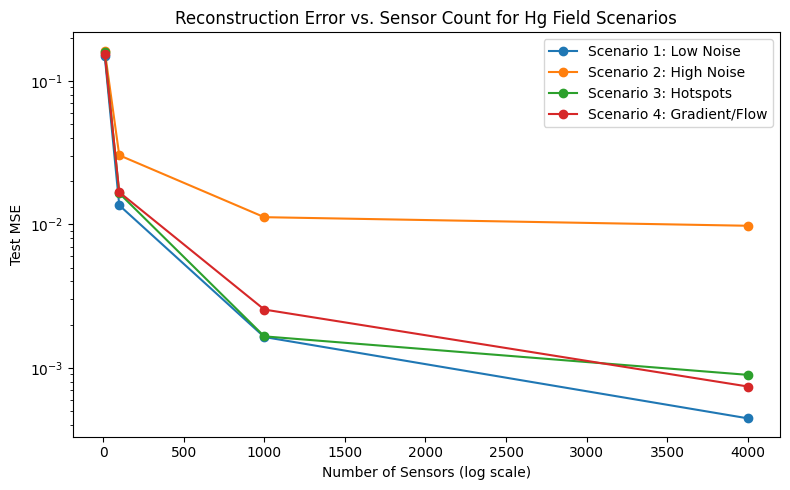

In [ ]:
import matplotlib.pyplot as plt

#plt.style.use('seaborn-darkgrid')

scenario_labels = {
    1: "Scenario 1: Low Noise",
    2: "Scenario 2: High Noise",
    3: "Scenario 3: Hotspots",
    4: "Scenario 4: Gradient/Flow"
}

plt.figure(figsize=(8,5))
for s_id in scenarios:
    plt.plot(sensor_counts, scenario_errors[s_id], marker='o', label=scenario_labels[s_id])

plt.yscale('log')
plt.xlabel("Number of Sensors (log scale)")
plt.ylabel("Test MSE")
plt.title("Reconstruction Error vs. Sensor Count for Hg Field Scenarios")
plt.legend()
plt.tight_layout()
plt.show()


Trained for sensor count 1, Test MSE: 0.2137
Trained for sensor count 10, Test MSE: 0.1593
Trained for sensor count 100, Test MSE: 0.0202
Trained for sensor count 1000, Test MSE: 0.0015


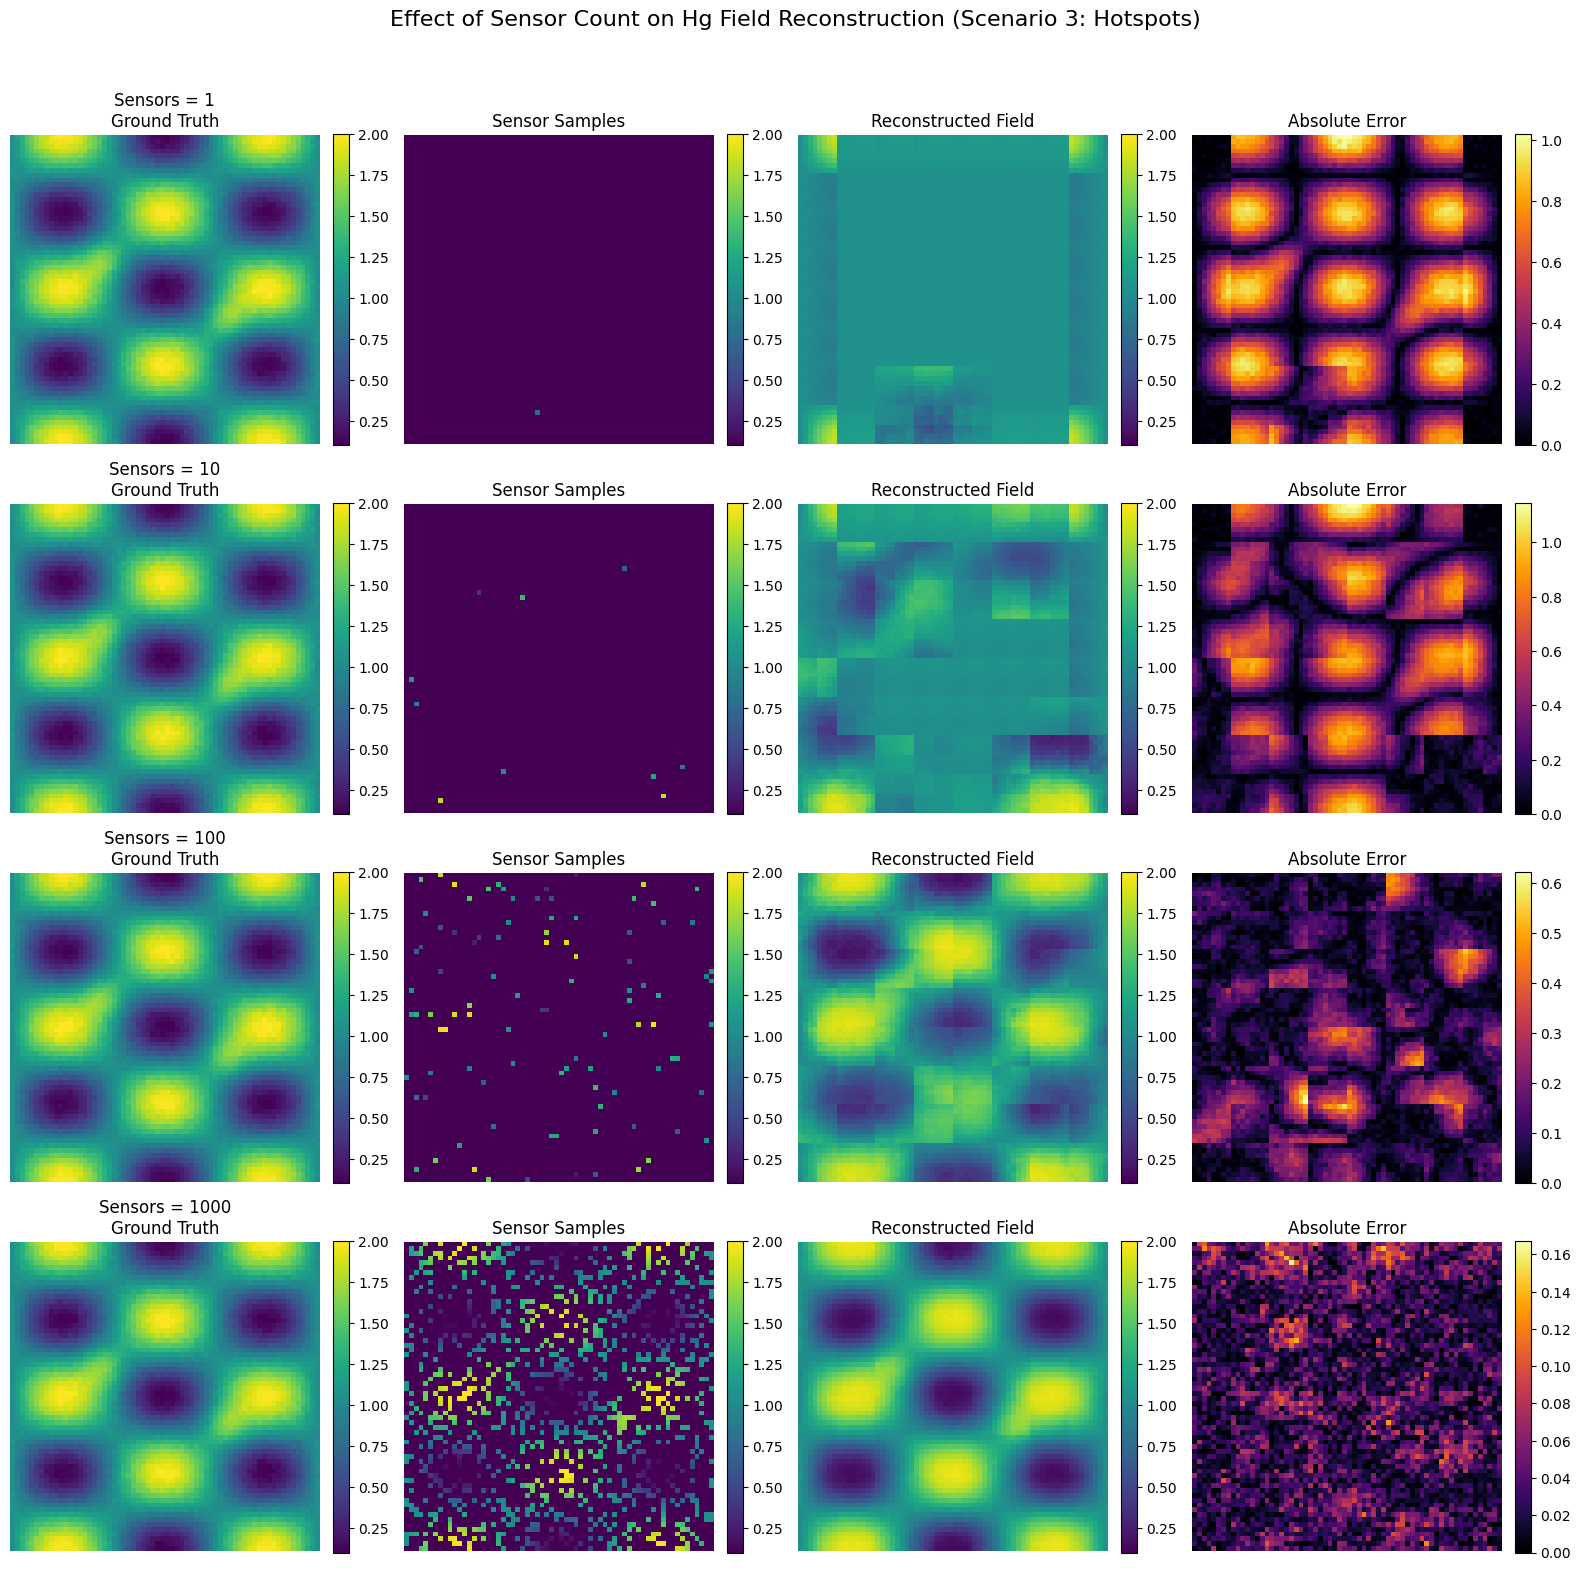

In [ ]:
import matplotlib.pyplot as plt
import torch

# Define the sensor counts to compare
sensor_counts = [1, 10, 100, 1000]
scenario_id = 3  # Scenario 3: Localized Hotspots

# Create a figure with 4 rows (one per sensor count) and 4 columns:
# Columns: Ground Truth, Sensor Samples, Reconstructed Field, Absolute Error
fig, axes = plt.subplots(len(sensor_counts), 4, figsize=(16, 16))

# Loop over sensor counts
for i, sc in enumerate(sensor_counts):
    # Train a model for the current sensor count in Scenario 3
    mse_val, model = train_autoencoder(scenario_id, sensor_count=sc, epochs=40, batch_size=32)
    print(f"Trained for sensor count {sc}, Test MSE: {mse_val:.4f}")

    # Get one sample for the current sensor count
    dataset = SensorFieldDataset(num_samples=1, sensor_count=sc, scenario_id=scenario_id)
    inp, tgt = dataset[0]  # inp: (2,64,64); tgt: (1,64,64)

    # Use the trained model to predict the full field
    model.eval()
    with torch.no_grad():
        pred = model(inp.unsqueeze(0))  # add batch dimension
        pred = pred.squeeze(0).squeeze(0).numpy()  # shape: (64,64)

    # Extract ground truth and sensor samples
    gt = tgt.squeeze(0).numpy()           # Ground Truth (64,64)
    sensor_samples = inp[0].numpy()         # Sensor samples (channel 0)
    error = abs(gt - pred)                  # Absolute error

    # Plot Ground Truth
    ax1 = axes[i, 0]
    im1 = ax1.imshow(gt, cmap='viridis', vmin=0.1, vmax=2.0)
    ax1.set_title(f"Sensors = {sc}\nGround Truth")
    ax1.axis('off')
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

    # Plot Sensor Samples
    ax2 = axes[i, 1]
    im2 = ax2.imshow(sensor_samples, cmap='viridis', vmin=0.1, vmax=2.0)
    ax2.set_title("Sensor Samples")
    ax2.axis('off')
    fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

    # Plot Reconstructed Field
    ax3 = axes[i, 2]
    im3 = ax3.imshow(pred, cmap='viridis', vmin=0.1, vmax=2.0)
    ax3.set_title("Reconstructed Field")
    ax3.axis('off')
    fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)

    # Plot Absolute Error
    ax4 = axes[i, 3]
    im4 = ax4.imshow(error, cmap='inferno', vmin=0, vmax=error.max())
    ax4.set_title("Absolute Error")
    ax4.axis('off')
    fig.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)

plt.suptitle("Effect of Sensor Count on Hg Field Reconstruction (Scenario 3: Hotspots)", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#more

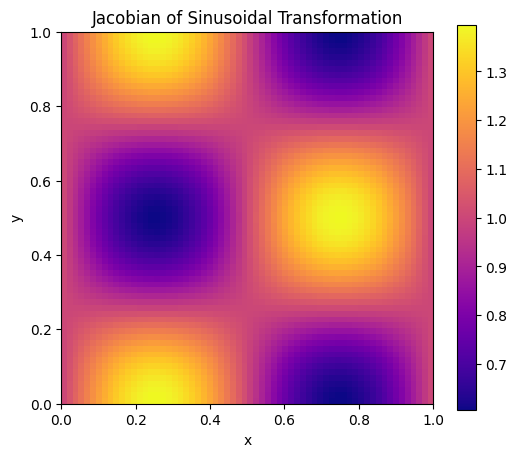

Trained for sensor count 1, Test MSE: 0.0005
Robust MSE (Jacobian-weighted) for sensor count 1: 0.0005
Trained for sensor count 10, Test MSE: 0.0005
Robust MSE (Jacobian-weighted) for sensor count 10: 0.0005
Trained for sensor count 100, Test MSE: 0.0005
Robust MSE (Jacobian-weighted) for sensor count 100: 0.0005
Trained for sensor count 1000, Test MSE: 0.0006
Robust MSE (Jacobian-weighted) for sensor count 1000: 0.0006


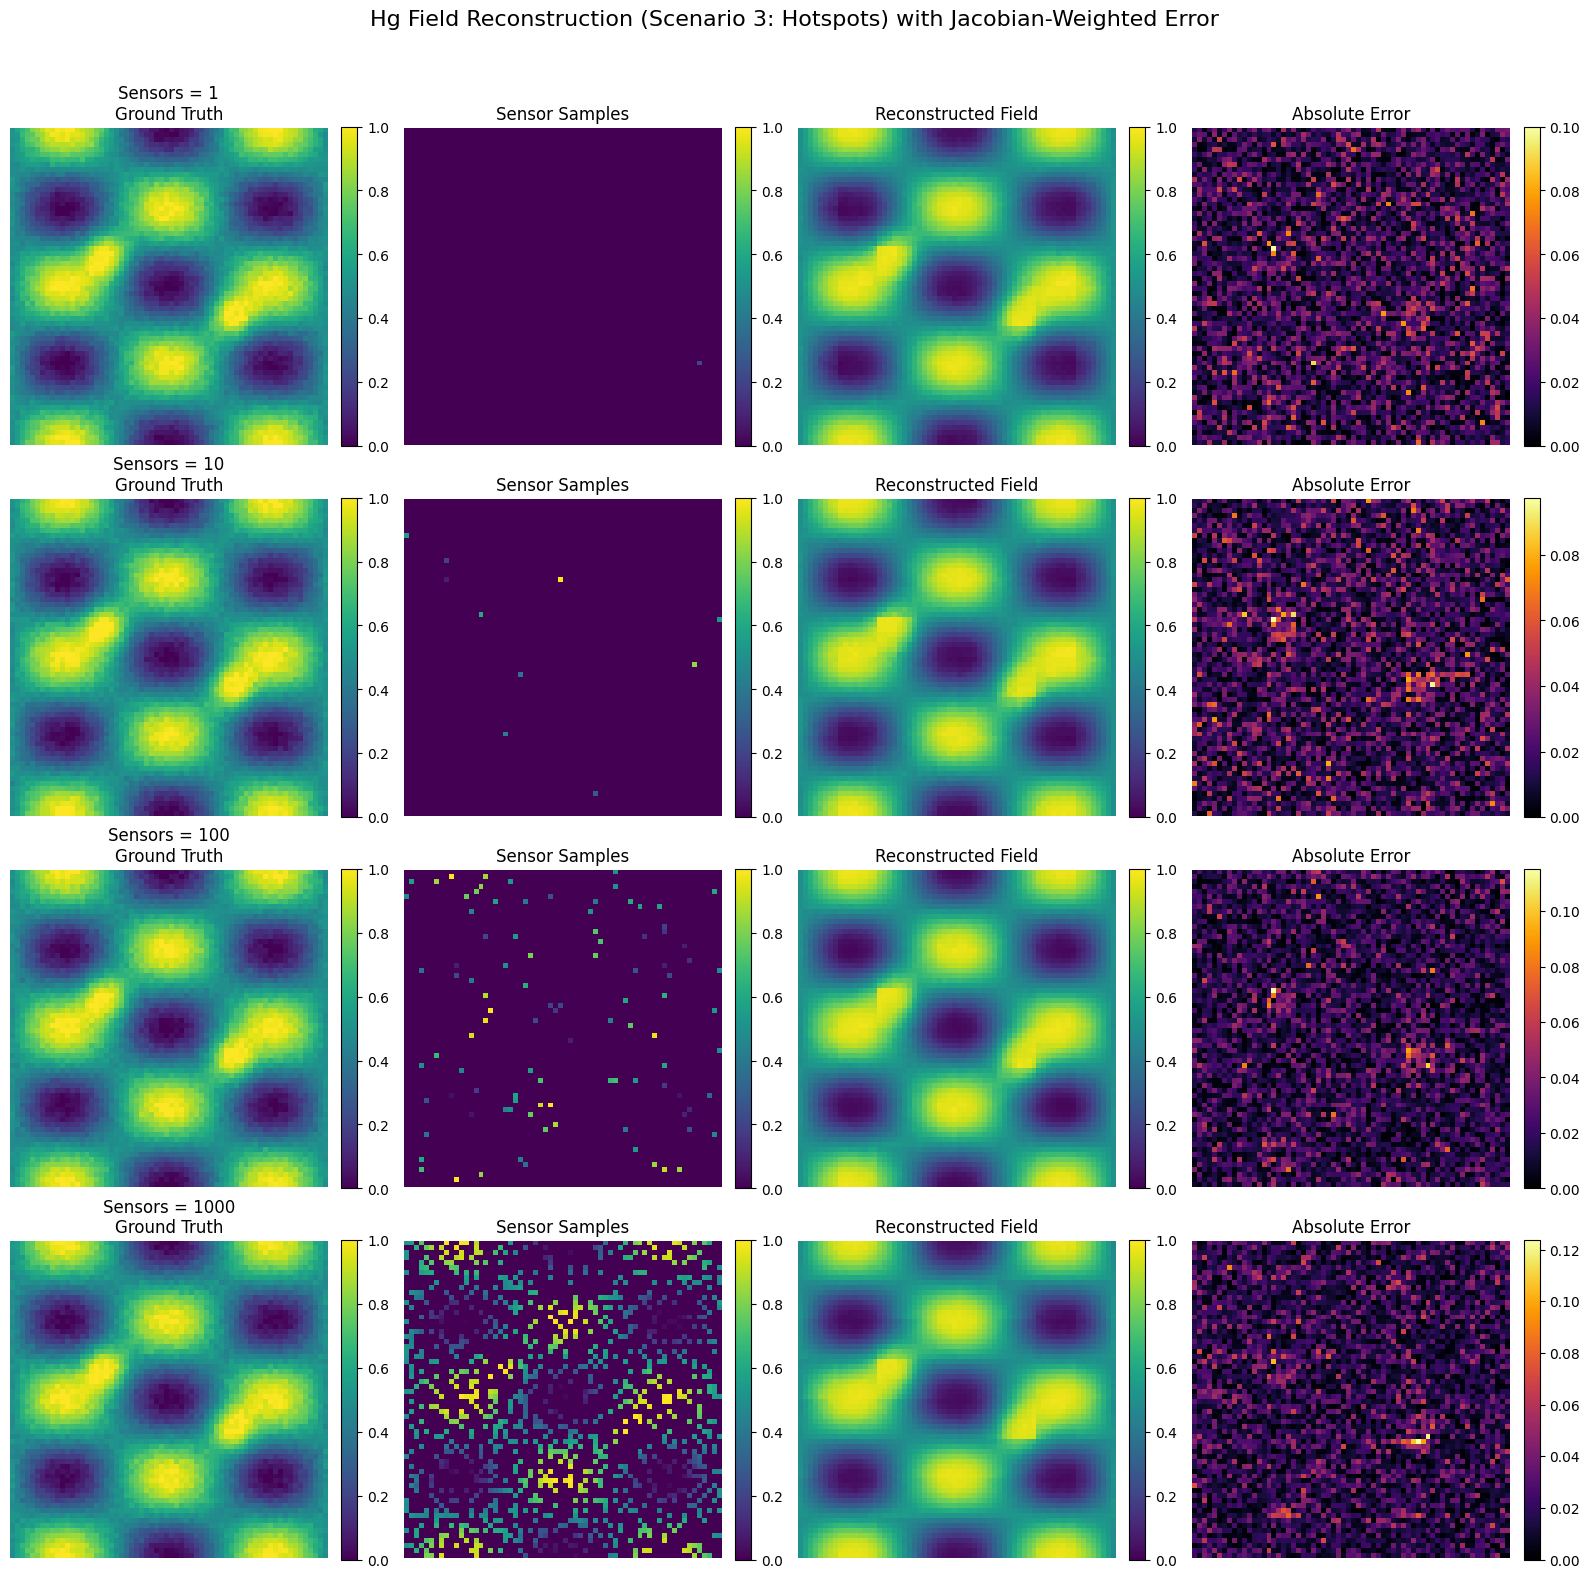

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Global grid parameters
grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

###############################################################################
# 1. Field Scenario 3: Localized Hotspots (Normalized to [0,1])
###############################################################################
def field_scenario_3():
    # Base field: sinusoidal variation normalized to [0,1]
    raw = np.sin(3*np.pi*xx) * np.cos(4*np.pi*yy)
    raw_norm = (raw - raw.min()) / (raw.max() - raw.min())
    field = raw_norm.copy()
    # Add hotspots
    hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
    for (cx, cy) in hotspot_centers:
        dist_sq = (xx - cx)**2 + (yy - cy)**2
        hotspot = np.exp(-dist_sq / 0.005)  # sharp, localized hotspot
        field += 0.5 * hotspot
    # Clip to [0,1]
    field = np.clip(field, 0, 1)
    # Add noise
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0, 1)

def generate_field(scenario_id):
    # Only scenario 3 is used
    if scenario_id == 3:
        return field_scenario_3()
    else:
        raise ValueError("Invalid scenario_id. Only scenario 3 is implemented.")

###############################################################################
# 2. SensorFieldDataset: Sample sensor_count points from the field.
###############################################################################
class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count, scenario_id):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [generate_field(scenario_id) for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]  # shape: (64,64)
        total_points = grid_size * grid_size
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)

        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0

        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)

        inp = np.stack([masked_field, mask], axis=0)  # (2,64,64)
        tgt = field[np.newaxis, ...]                   # (1,64,64)
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

###############################################################################
# 3. Complex Autoencoder with Attention and LSTM
###############################################################################
class ComplexAutoencoder(nn.Module):
    def __init__(self):
        super(ComplexAutoencoder, self).__init__()
        # Encoder: CNN layers
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),         # 64x64 -> 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),         # 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)          # 16x16 -> 8x8
        )
        # LSTM expects sequence input: flatten spatial dims (8x8=64) with 128 features
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        # Multihead attention: expects (seq_len, batch, embed_dim)
        self.attention = nn.MultiheadAttention(embed_dim=128, num_heads=4)
        # Decoder: CNN Transposed Convolutions to upscale back to 64x64
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),  # 8x8 -> 16x16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),   # 16x16 -> 32x32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),    # 32x32 -> 64x64
            nn.Sigmoid()  # Output in [0,1]
        )

    def forward(self, x):
        # x shape: (batch, 2, 64, 64)
        encoded = self.encoder(x)              # (batch, 128, 8, 8)
        batch_size = encoded.shape[0]
        # Flatten spatial dims to sequence: (batch, 64, 128)
        seq = encoded.view(batch_size, 128, -1).permute(0, 2, 1)
        # LSTM processing
        lstm_out, _ = self.lstm(seq)           # (batch, 64, 128)
        # Prepare for attention: (seq_len, batch, embed_dim)
        attn_input = lstm_out.permute(1, 0, 2)
        attn_output, _ = self.attention(attn_input, attn_input, attn_input)
        # Residual connection: add attention output back
        attn_out = attn_output + attn_input    # (seq_len, batch, 128)
        # Convert back to (batch, 128, 8,8)
        attn_out = attn_out.permute(1, 2, 0).contiguous().view(batch_size, 128, 8, 8)
        # Decode back to full image
        out = self.decoder(attn_out)           # (batch, 1, 64, 64)
        return out

###############################################################################
# 4. Training Routine (for scenario 3 only)
###############################################################################
def train_autoencoder(scenario_id, sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count, scenario_id=scenario_id)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count, scenario_id=scenario_id)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = ComplexAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()

    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

###############################################################################
# 5. Sinusoidal Transformation & Jacobian for Error Weighting
###############################################################################
alpha = 0.1
def T(x, y, alpha=alpha):
    """Coordinate transformation: simple sinusoidal perturbation."""
    u = x + alpha * np.sin(2 * np.pi * y)
    v = y + alpha * np.cos(2 * np.pi * x)
    return u, v

def jacobian_T(x, y, alpha=alpha):
    """
    Computes the Jacobian determinant of T(x,y) = (x + alpha*sin(2*pi*y), y + alpha*cos(2*pi*x)).
    du/dx = 1;      du/dy = alpha*2*pi*cos(2*pi*y)
    dv/dx = -alpha*2*pi*sin(2*pi*x);   dv/dy = 1.
    Jacobian = 1 + alpha**2*(2*pi)**2 * cos(2*pi*y)*sin(2*pi*x)
    """
    du_dx = 1.0
    du_dy = alpha * 2 * np.pi * np.cos(2 * np.pi * y)
    dv_dx = -alpha * 2 * np.pi * np.sin(2 * np.pi * x)
    dv_dy = 1.0
    return du_dx * dv_dy - du_dy * dv_dx

# Compute the Jacobian over the grid for visualization
J = jacobian_T(xx, yy, alpha)

###############################################################################
# 6. Visualization
###############################################################################
# First, visualize the Jacobian transformation
plt.figure(figsize=(6,5))
plt.title("Jacobian of Sinusoidal Transformation")
im = plt.imshow(J, cmap='plasma', extent=(0,1,0,1))
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar(im)
plt.show()

# Now, run experiment for different sensor counts and show error transformation
sensor_counts = [1, 10, 100, 1000]
scenario_id = 3  # Hotspots only

fig, axes = plt.subplots(len(sensor_counts), 4, figsize=(16, 16))
for i, sc in enumerate(sensor_counts):
    mse_val, model = train_autoencoder(scenario_id, sensor_count=sc, epochs=40, batch_size=32)
    print(f"Trained for sensor count {sc}, Test MSE: {mse_val:.4f}")

    dataset = SensorFieldDataset(num_samples=1, sensor_count=sc, scenario_id=scenario_id)
    inp, tgt = dataset[0]  # inp: (2,64,64); tgt: (1,64,64)

    model.eval()
    with torch.no_grad():
        pred = model(inp.unsqueeze(0))  # (1,1,64,64)
        pred = pred.squeeze(0).squeeze(0).numpy()  # (64,64)

    gt = tgt.squeeze(0).numpy()  # Ground Truth (64,64)
    sensor_samples = inp[0].numpy()  # Sensor channel

    # Compute squared error and weight it with the Jacobian
    squared_error = (gt - pred)**2
    weighted_error = squared_error * J  # elementwise weighting
    robust_mse = np.mean(weighted_error)
    print(f"Robust MSE (Jacobian-weighted) for sensor count {sc}: {robust_mse:.4f}")

    # For visualization, also compute absolute error (unweighted)
    error = np.abs(gt - pred)

    # Plot Ground Truth
    ax1 = axes[i, 0]
    im1 = ax1.imshow(gt, cmap='viridis', vmin=0, vmax=1)
    ax1.set_title(f"Sensors = {sc}\nGround Truth")
    ax1.axis('off')
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

    # Plot Sensor Samples
    ax2 = axes[i, 1]
    im2 = ax2.imshow(sensor_samples, cmap='viridis', vmin=0, vmax=1)
    ax2.set_title("Sensor Samples")
    ax2.axis('off')
    fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

    # Plot Reconstructed Field
    ax3 = axes[i, 2]
    im3 = ax3.imshow(pred, cmap='viridis', vmin=0, vmax=1)
    ax3.set_title("Reconstructed Field")
    ax3.axis('off')
    fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)

    # Plot Absolute Error (unweighted)
    ax4 = axes[i, 3]
    im4 = ax4.imshow(error, cmap='inferno', vmin=0, vmax=error.max())
    ax4.set_title("Absolute Error")
    ax4.axis('off')
    fig.colorbar(im4, ax=ax4, fraction=0.046, pad=0.04)

plt.suptitle("Hg Field Reconstruction (Scenario 3: Hotspots) with Jacobian-Weighted Error", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Sensor count 1, Test MSE: 0.0620
Sensor count 10, Test MSE: 0.0500
Sensor count 100, Test MSE: 0.0107
Sensor count 1000, Test MSE: 0.0016


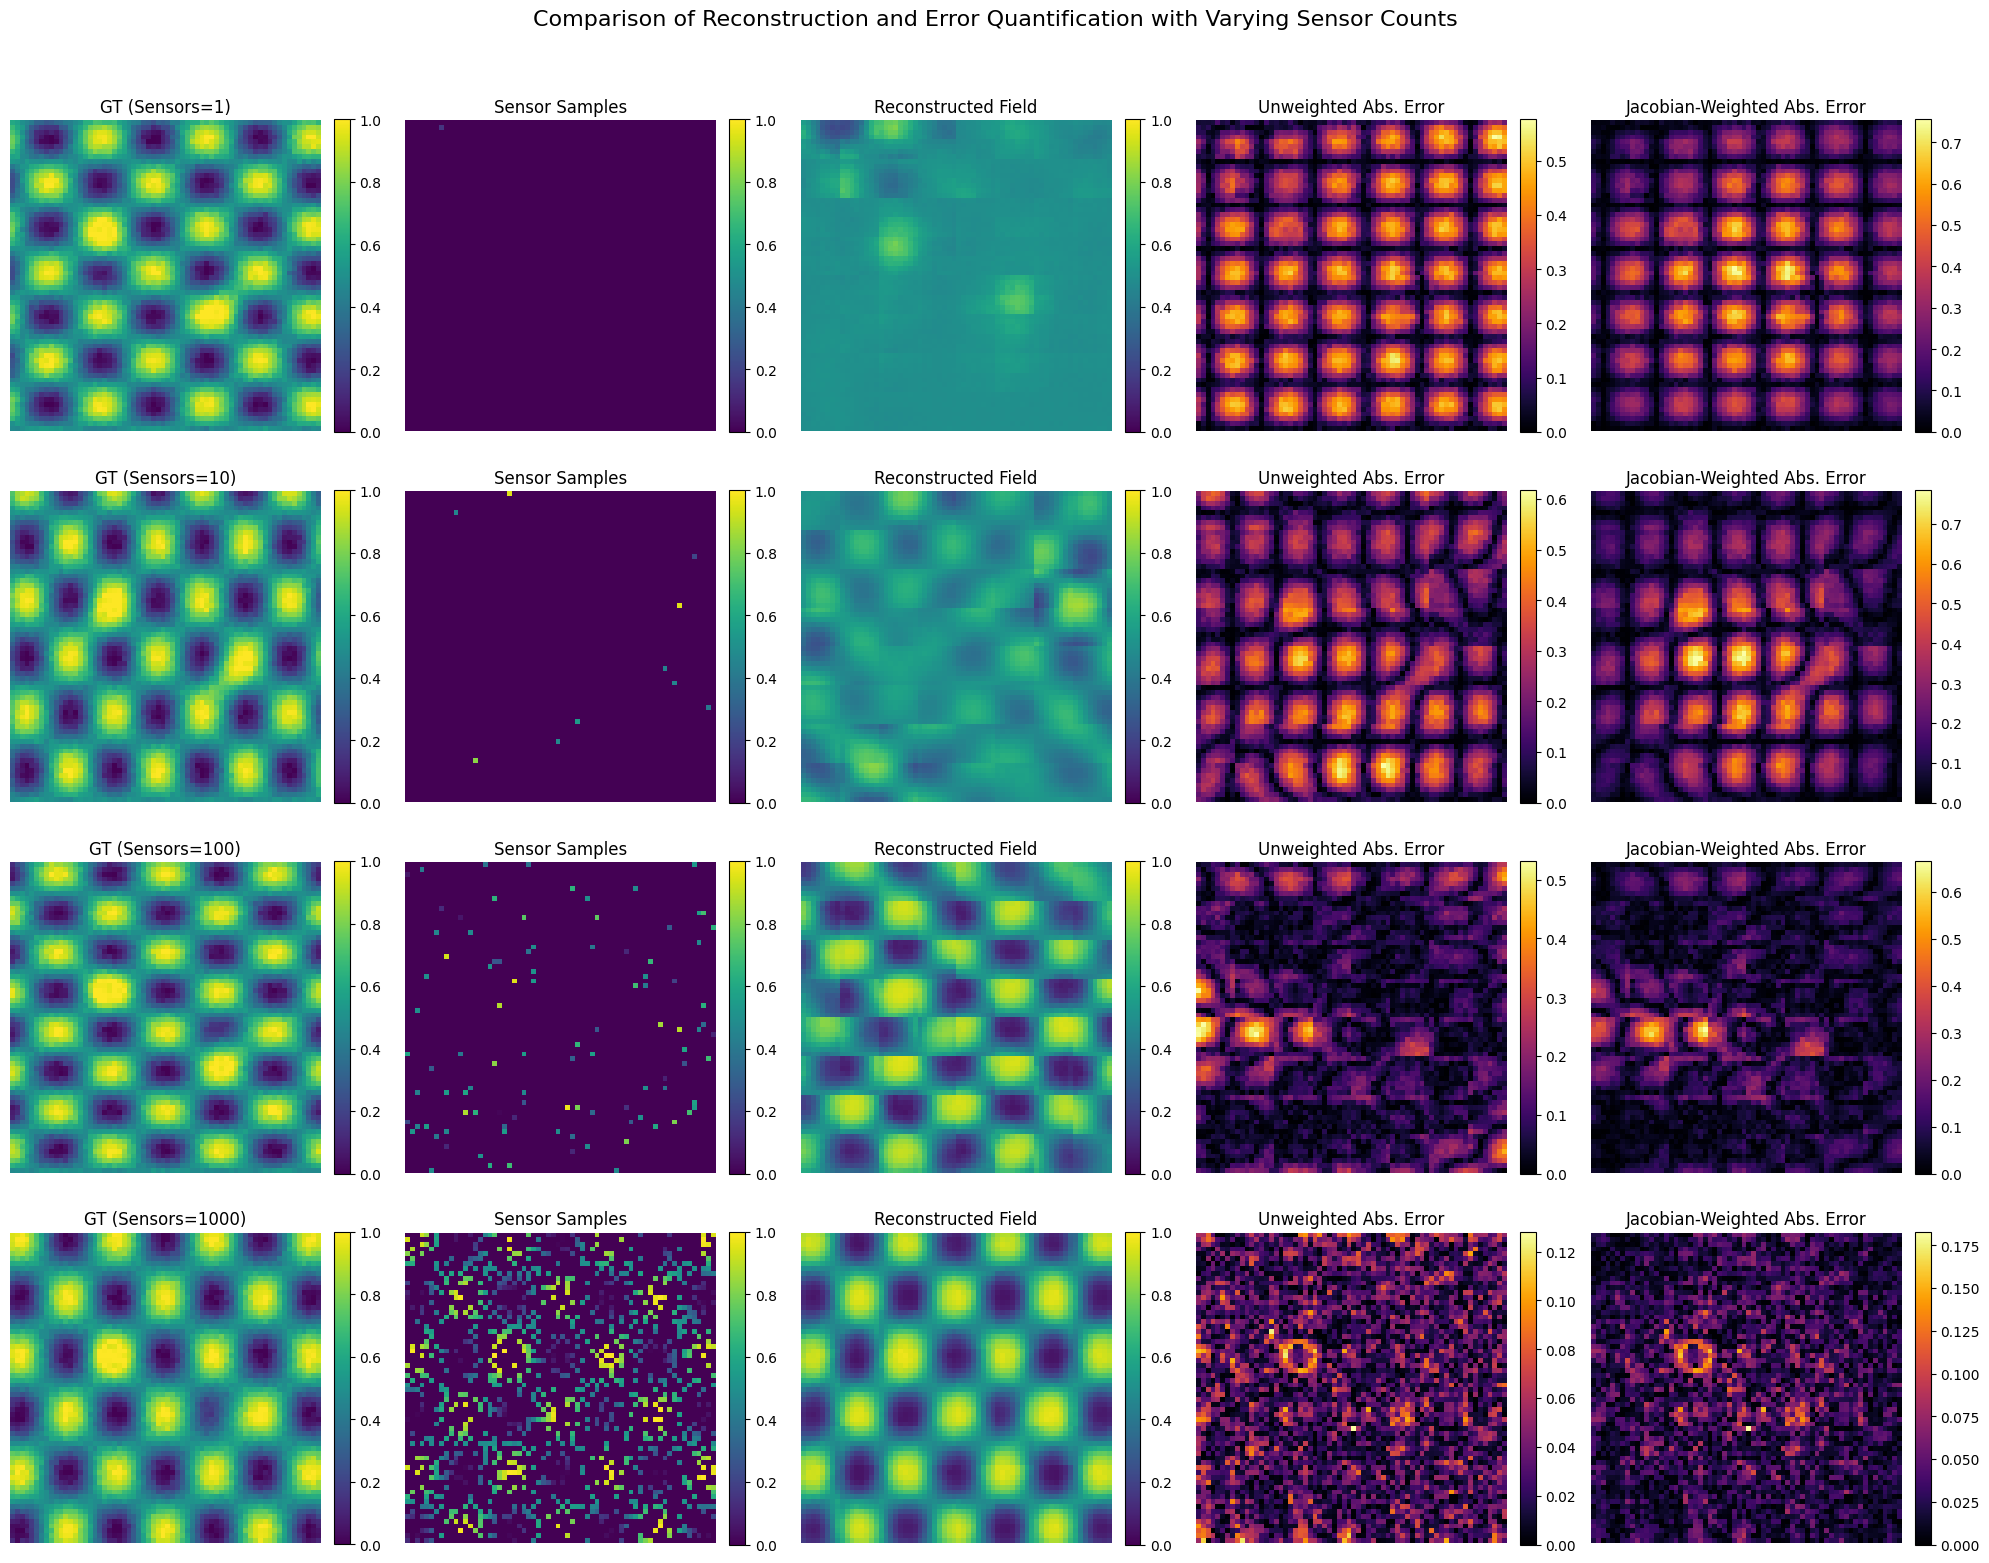

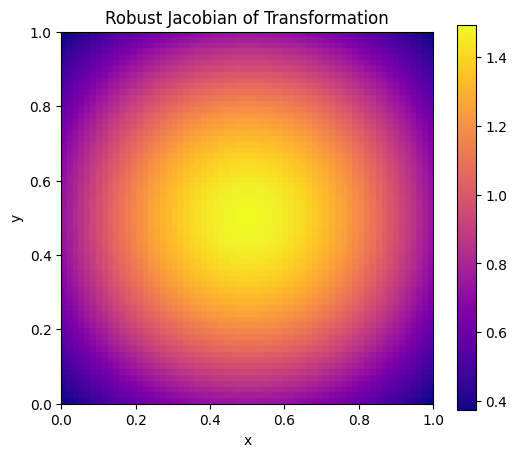

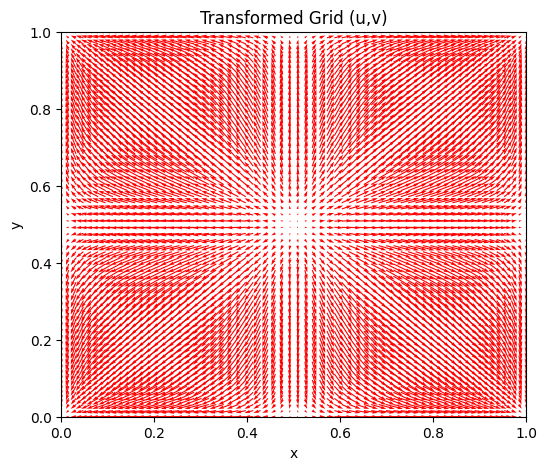

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

###############################################################################
# 1. Multiple Sinusoidal Scenarios Generator (with optional hotspots)
###############################################################################
grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

def generate_random_sinusoidal_field(add_hotspots=True):
    """
    Generates a field from a sinusoidal function with random frequency and phase.
    The base field is normalized to [0,1]. Optionally adds localized hotspots.
    """
    # Random frequencies and phases in a tractable range
    freq_x = np.random.uniform(2, 4)
    freq_y = np.random.uniform(2, 4)
    phase_x = np.random.uniform(0, 2*np.pi)
    phase_y = np.random.uniform(0, 2*np.pi)

    # Generate base sinusoidal field (the sum is shifted to [0,1])
    base = np.sin(2*np.pi*freq_x*xx + phase_x) * np.sin(2*np.pi*freq_y*yy + phase_y)
    base_norm = (base - base.min()) / (base.max()-base.min())

    field = base_norm.copy()

    # Optionally add hotspots to increase diversity
    if add_hotspots:
        hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
        for (cx, cy) in hotspot_centers:
            dist_sq = (xx - cx)**2 + (yy - cy)**2
            hotspot = np.exp(-dist_sq / 0.005)  # very localized
            field += 0.3 * hotspot
        field = np.clip(field, 0, 1)

    # Add a bit of noise
    noise = np.random.normal(0, 0.02, size=field.shape)
    field = np.clip(field + noise, 0, 1)
    return field

###############################################################################
# 2. SensorFieldDataset: Samples a field and then randomly selects sensor points.
###############################################################################
class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        # Each sample gets its own random sinusoidal field.
        self.fields = [generate_random_sinusoidal_field(add_hotspots=True) for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]  # shape: (64,64)
        total_points = grid_size * grid_size
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)

        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0

        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)
        inp = np.stack([masked_field, mask], axis=0)  # (2,64,64)
        tgt = field[np.newaxis, ...]                   # (1,64,64)
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

###############################################################################
# 3. Complex Autoencoder with LSTM and Attention
###############################################################################
class ComplexAutoencoder(nn.Module):
    def __init__(self):
        super(ComplexAutoencoder, self).__init__()
        # Encoder: CNN layers
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),         # 64x64 -> 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),         # 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)          # 16x16 -> 8x8
        )
        # LSTM layer: treat spatial positions as a sequence
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        # Multihead Attention: capture nonlocal interactions.
        self.attention = nn.MultiheadAttention(embed_dim=128, num_heads=4)
        # Decoder: Upsample via ConvTranspose2d layers
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),  # 8x8 -> 16x16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),   # 16x16 -> 32x32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),    # 32x32 -> 64x64
            nn.Sigmoid()  # Output in [0,1]
        )

    def forward(self, x):
        # x: (batch, 2, 64,64)
        encoded = self.encoder(x)             # (batch, 128, 8,8)
        batch_size = encoded.shape[0]
        # Reshape to sequence: (batch, 64, 128) [64 = 8x8]
        seq = encoded.view(batch_size, 128, -1).permute(0, 2, 1)
        # LSTM processing
        lstm_out, _ = self.lstm(seq)          # (batch, 64, 128)
        # Prepare for attention: (seq_len, batch, embed_dim)
        attn_input = lstm_out.permute(1, 0, 2)
        attn_output, _ = self.attention(attn_input, attn_input, attn_input)
        # Residual connection
        attn_out = attn_output + attn_input   # (seq_len, batch, 128)
        # Reshape back to (batch, 128, 8,8)
        attn_out = attn_out.permute(1, 2, 0).contiguous().view(batch_size, 128, 8, 8)
        out = self.decoder(attn_out)          # (batch, 1, 64,64)
        return out

###############################################################################
# 4. Robust Jacobian Transformation
#
# We want a transformation T that, when applied to the grid, transforms the
# sinusoidal profile to a uniform one. Here we use the marginal cumulative
# functions (inverse transform) for the chosen sinusoidal form.
#
# For the 1D case, define:
#   u(x) = ( x + (1-cos(pi*x))/pi ) / (1+2/pi)
# and similarly for v(y). Then T(x,y) = (u(x), v(y)).
###############################################################################
def T_grid(x, y):
    """
    Applies the transformation T to grid coordinates.
    """
    C = 1 + 2/np.pi
    u = (x + (1 - np.cos(np.pi * x)) / np.pi) / C
    v = (y + (1 - np.cos(np.pi * y)) / np.pi) / C
    return u, v

def jacobian_T_robust(x, y):
    """
    Computes the Jacobian determinant of T.
    For u(x) = [x + (1-cos(pi*x))/pi] / C, we have
       du/dx = [1 + sin(pi*x)]/C.
    Similarly, dv/dy = [1 + sin(pi*y)]/C.
    Thus, the Jacobian is:
       J(x,y) = (1 + sin(pi*x))*(1 + sin(pi*y)) / C^2.
    """
    C = 1 + 2/np.pi
    du_dx = (1 + np.sin(np.pi * x)) / C
    dv_dy = (1 + np.sin(np.pi * y)) / C
    return du_dx * dv_dy

# Precompute transformation for visualization: original grid and transformed grid.
u_grid, v_grid = T_grid(xx, yy)
J_grid = jacobian_T_robust(xx, yy)

###############################################################################
# 5. Training Routine (on multiple sinusoidal scenarios)
###############################################################################
def train_autoencoder(sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = ComplexAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()

    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

###############################################################################
# 6. Visualization: Show transformation for grids and compare errors.
#
# For each sensor count, we display:
#   - Ground Truth field,
#   - Sensor Samples,
#   - Reconstructed Field,
#   - Unweighted Absolute Error,
#   - Jacobian-weighted Absolute Error.
###############################################################################
sensor_counts = [1, 10, 100, 1000]
fig, axes = plt.subplots(len(sensor_counts), 5, figsize=(20, 4*len(sensor_counts)))

for i, sc in enumerate(sensor_counts):
    mse_val, model = train_autoencoder(sensor_count=sc, epochs=40, batch_size=32)
    print(f"Sensor count {sc}, Test MSE: {mse_val:.4f}")

    # Get one sample
    dataset = SensorFieldDataset(num_samples=1, sensor_count=sc)
    inp, tgt = dataset[0]  # inp: (2,64,64); tgt: (1,64,64)

    model.eval()
    with torch.no_grad():
        pred = model(inp.unsqueeze(0))
        pred = pred.squeeze(0).squeeze(0).numpy()  # (64,64)

    gt = tgt.squeeze(0).numpy()  # (64,64)
    sensor_samples = inp[0].numpy()

    # Compute errors:
    abs_error = np.abs(gt - pred)
    weighted_error = abs_error * J_grid  # Jacobian weighting

    # Column 1: Ground Truth
    ax = axes[i, 0]
    im = ax.imshow(gt, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(f"GT (Sensors={sc})")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 2: Sensor Samples
    ax = axes[i, 1]
    im = ax.imshow(sensor_samples, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Sensor Samples")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 3: Reconstructed Field
    ax = axes[i, 2]
    im = ax.imshow(pred, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Reconstructed Field")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 4: Unweighted Absolute Error
    ax = axes[i, 3]
    im = ax.imshow(abs_error, cmap='inferno', vmin=0, vmax=abs_error.max())
    ax.set_title("Unweighted Abs. Error")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 5: Jacobian-Weighted Absolute Error
    ax = axes[i, 4]
    im = ax.imshow(weighted_error, cmap='inferno', vmin=0, vmax=weighted_error.max())
    ax.set_title("Jacobian-Weighted Abs. Error")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Comparison of Reconstruction and Error Quantification with Varying Sensor Counts", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

###############################################################################
# 7. Visualize the Jacobian Transformation on the Grid
###############################################################################
plt.figure(figsize=(6,5))
plt.title("Robust Jacobian of Transformation")
im = plt.imshow(J_grid, cmap='plasma', extent=(0,1,0,1))
plt.xlabel("x")
plt.ylabel("y")
plt.colorbar(im)
plt.show()

# Also, visualize the transformed grid coordinates.
plt.figure(figsize=(6,5))
plt.title("Transformed Grid (u,v)")
plt.quiver(xx, yy, u_grid-xx, v_grid-yy, angles='xy', scale_units='xy', scale=1, color='red')
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(0,1)
plt.ylim(0,1)
plt.show()

Sensor count 1, Test MSE: 0.0619
Robust (Jacobian-weighted) MSE for sensor count 1: 0.1991
Sensor count 10, Test MSE: 0.0497
Robust (Jacobian-weighted) MSE for sensor count 10: 0.1614
Sensor count 100, Test MSE: 0.0109
Robust (Jacobian-weighted) MSE for sensor count 100: 0.0748
Sensor count 1000, Test MSE: 0.0015
Robust (Jacobian-weighted) MSE for sensor count 1000: 0.0318


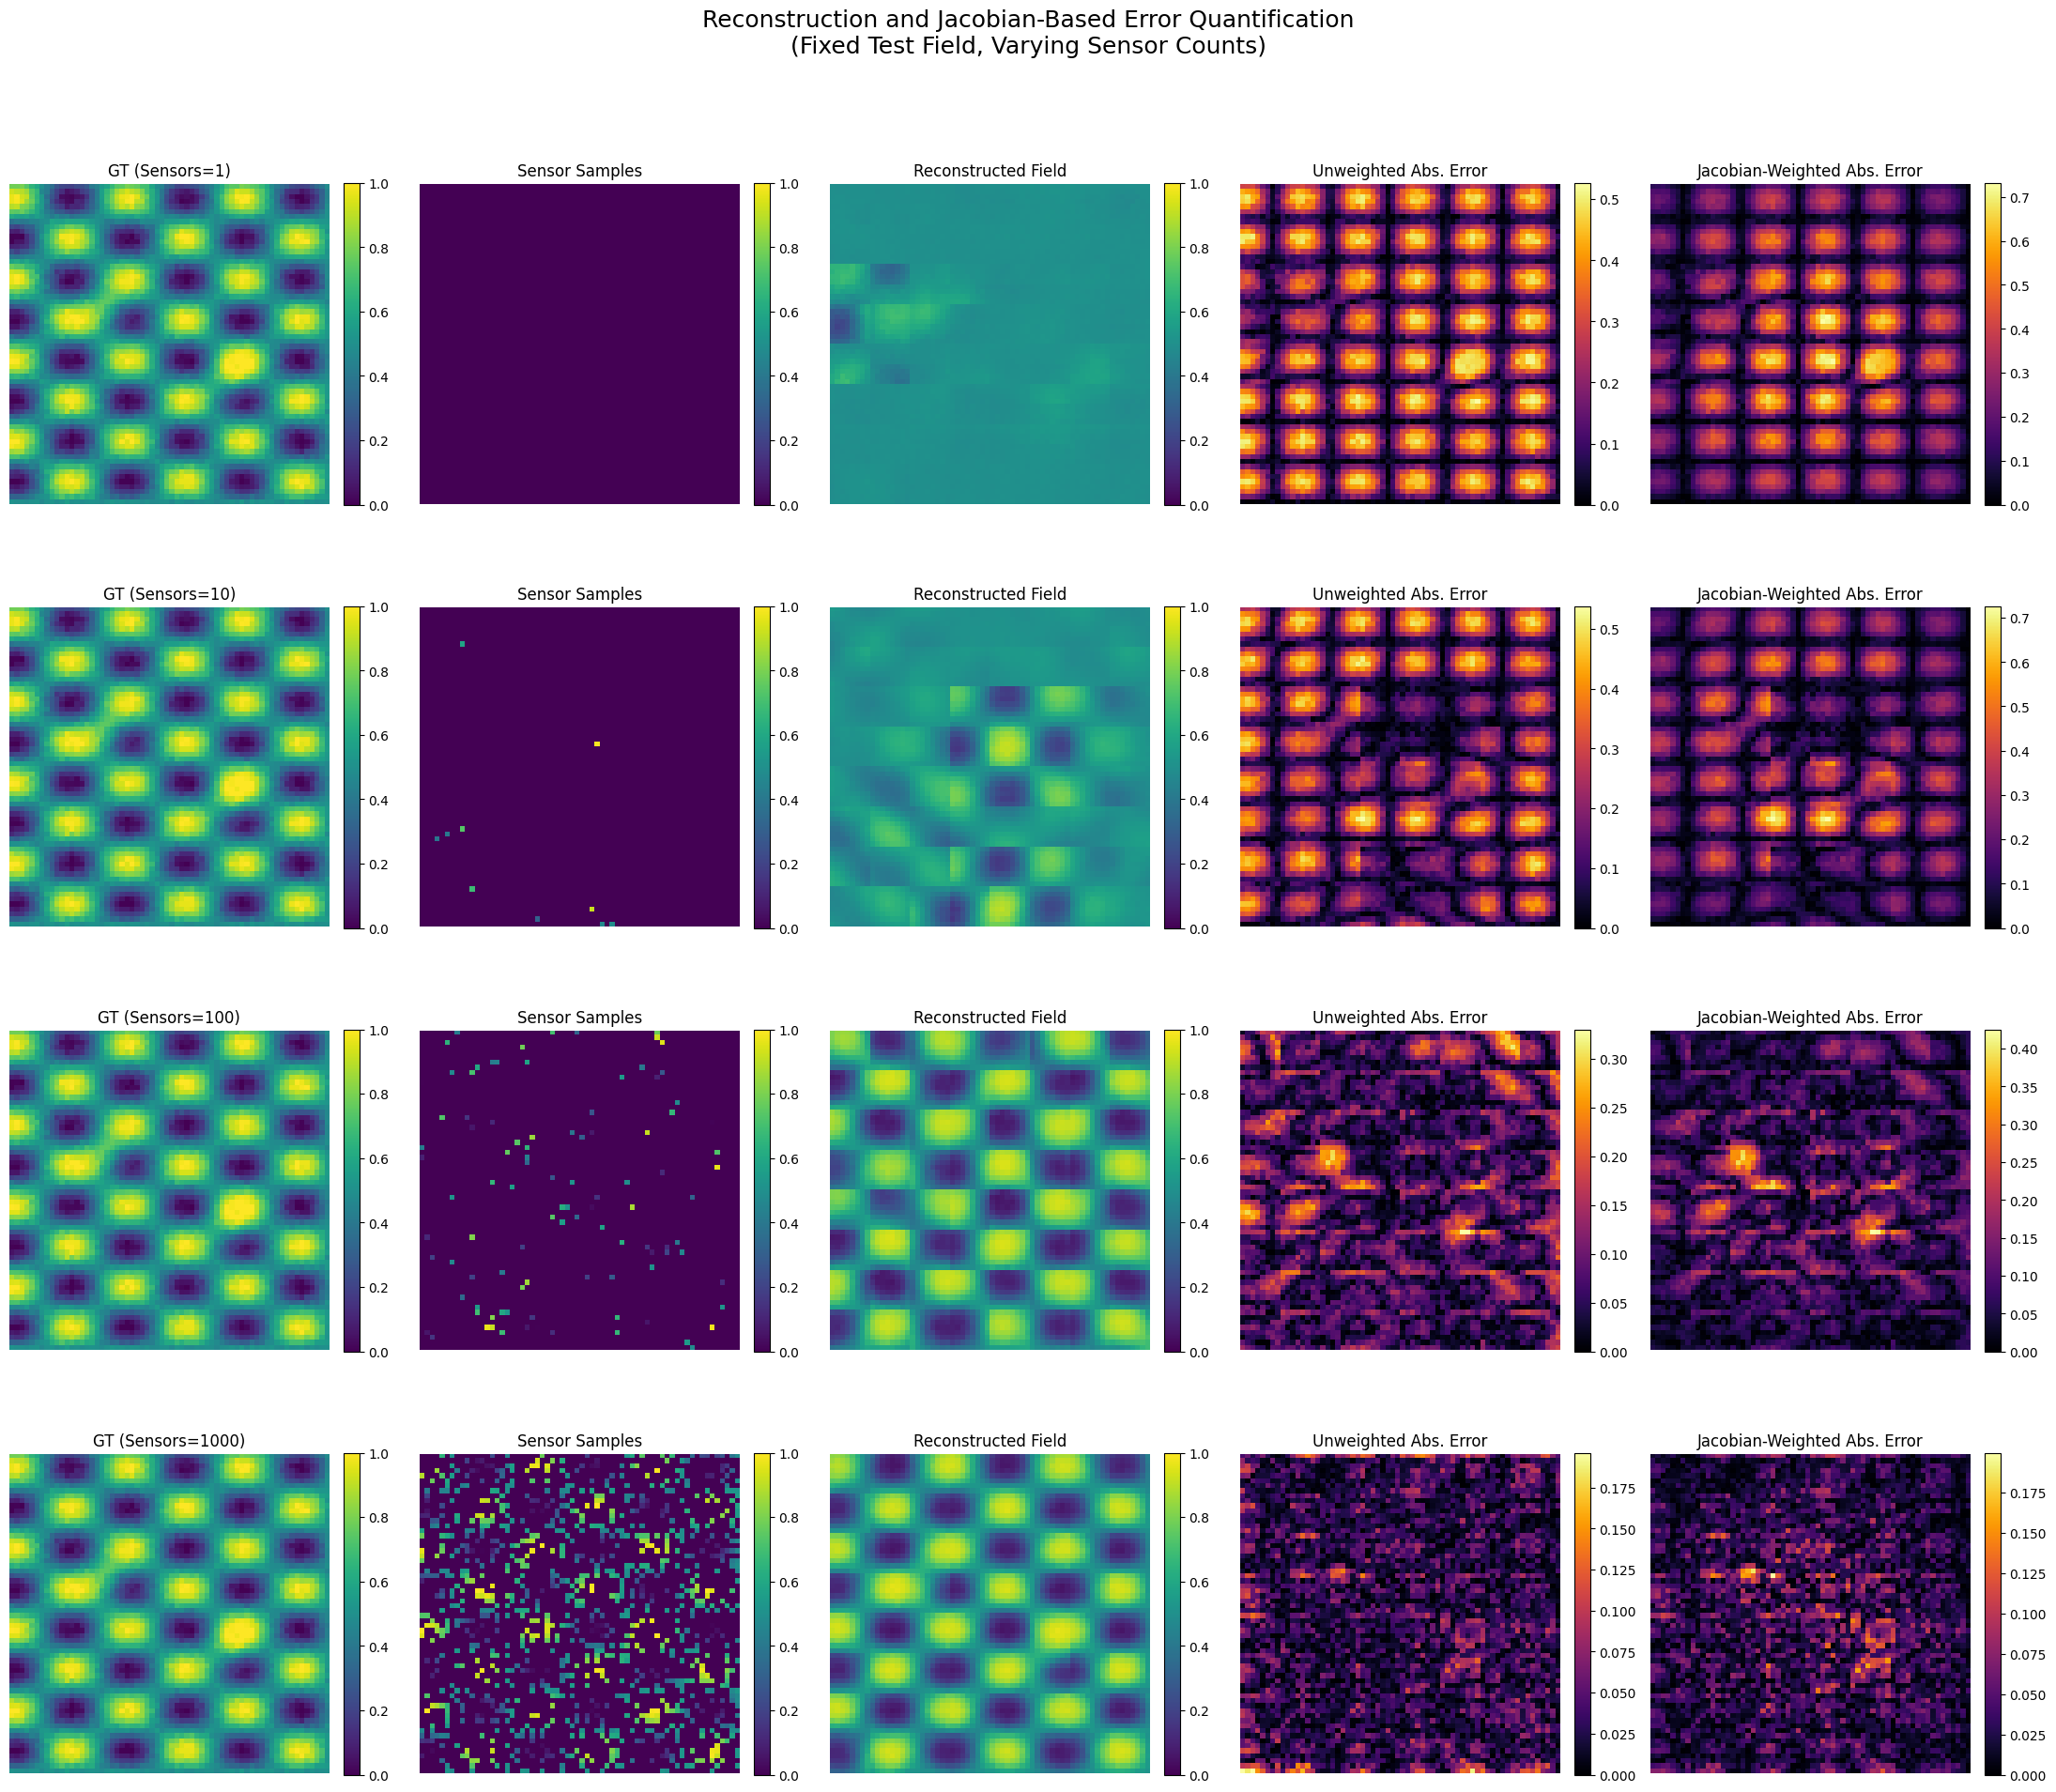

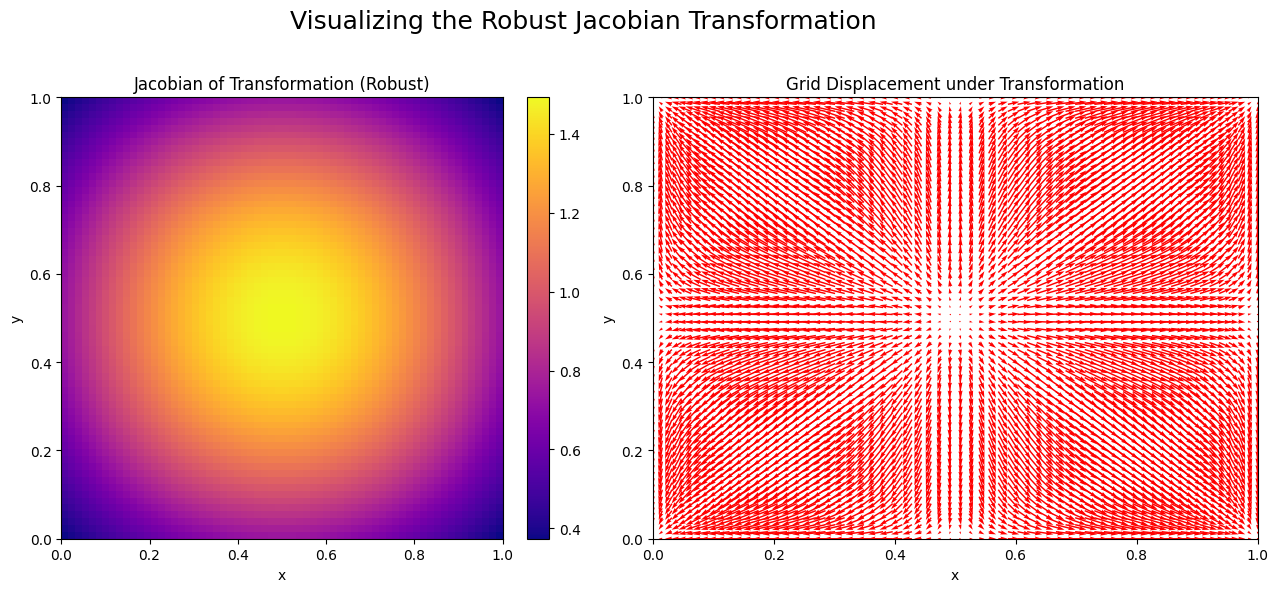

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

###############################################################################
# 1. Multiple Sinusoidal Field Generator with Hotspots
###############################################################################
grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

def generate_random_sinusoidal_field(add_hotspots=True):
    """
    Generates a field from a sinusoidal function with random frequency/phase.
    The base field is normalized to [0,1]. Optionally adds localized hotspots.
    """
    freq_x = np.random.uniform(2, 4)
    freq_y = np.random.uniform(2, 4)
    phase_x = np.random.uniform(0, 2*np.pi)
    phase_y = np.random.uniform(0, 2*np.pi)

    base = np.sin(2*np.pi*freq_x*xx + phase_x) * np.sin(2*np.pi*freq_y*yy + phase_y)
    base_norm = (base - base.min()) / (base.max()-base.min())
    field = base_norm.copy()
    if add_hotspots:
        hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
        for (cx, cy) in hotspot_centers:
            dist_sq = (xx - cx)**2 + (yy - cy)**2
            hotspot = np.exp(-dist_sq / 0.005)
            field += 0.3 * hotspot
        field = np.clip(field, 0, 1)
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0, 1)

###############################################################################
# 2. Dataset for Training (each sample is a new random field)
###############################################################################
class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [generate_random_sinusoidal_field(add_hotspots=True) for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]  # shape: (64,64)
        total_points = grid_size * grid_size
        # Random sensor indices for training
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)
        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0
        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)
        inp = np.stack([masked_field, mask], axis=0)  # (2,64,64)
        tgt = field[np.newaxis, ...]                   # (1,64,64)
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

###############################################################################
# 3. Complex Autoencoder with LSTM and Attention Layers
###############################################################################
class ComplexAutoencoder(nn.Module):
    def __init__(self):
        super(ComplexAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64x64 -> 32x32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32x32 -> 16x16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 16x16 -> 8x8
        )
        # LSTM for sequence processing: treat 8x8 grid as sequence of 64 vectors (128 dim each)
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        # Multihead Attention (expects (seq_len, batch, embed_dim))
        self.attention = nn.MultiheadAttention(embed_dim=128, num_heads=4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),  # 8x8 -> 16x16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),   # 16x16 -> 32x32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),    # 32x32 -> 64x64
            nn.Sigmoid()  # Output in [0,1]
        )

    def forward(self, x):
        encoded = self.encoder(x)             # (batch, 128, 8,8)
        batch_size = encoded.shape[0]
        # Reshape to sequence: (batch, 64, 128)
        seq = encoded.view(batch_size, 128, -1).permute(0, 2, 1)
        lstm_out, _ = self.lstm(seq)           # (batch, 64, 128)
        # Prepare for attention: (seq_len, batch, embed_dim)
        attn_input = lstm_out.permute(1, 0, 2)
        attn_output, _ = self.attention(attn_input, attn_input, attn_input)
        attn_out = attn_output + attn_input   # Residual connection
        # Reshape back to (batch, 128, 8,8)
        attn_out = attn_out.permute(1, 2, 0).contiguous().view(batch_size, 128, 8, 8)
        out = self.decoder(attn_out)          # (batch, 1, 64,64)
        return out

###############################################################################
# 4. Robust Jacobian Transformation
#
# We want to transform a sinusoidal profile to a uniform one.
# Here we use the inverse transform of a canonical 1D sinusoidal mapping.
#
# For 1D, define:
#   u(x) = [x + (1-cos(pi*x))/pi] / C,   with C = 1+2/pi.
# Then the Jacobian in 1D is: du/dx = [1 + sin(pi*x)]/C.
# For 2D, T(x,y) = (u(x), v(y)) with the same form in each coordinate,
# and the overall Jacobian is: J(x,y) = (1+sin(pi*x))*(1+sin(pi*y)) / C^2.
###############################################################################
def T_grid(x, y):
    C = 1 + 2/np.pi
    u = (x + (1 - np.cos(np.pi * x)) / np.pi) / C
    v = (y + (1 - np.cos(np.pi * y)) / np.pi) / C
    return u, v

def jacobian_T_robust(x, y):
    C = 1 + 2/np.pi
    du_dx = (1 + np.sin(np.pi * x)) / C
    dv_dy = (1 + np.sin(np.pi * y)) / C
    return du_dx * dv_dy

# Precompute transformed grid and Jacobian on the fixed grid
u_grid, v_grid = T_grid(xx, yy)
J_grid = jacobian_T_robust(xx, yy)

###############################################################################
# 5. Training Routine (using diverse training samples)
###############################################################################
def train_autoencoder(sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = ComplexAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()

    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

###############################################################################
# 6. Fixed Test Field & Fixed Sensor Sampling
#
# We generate one fixed test field and then, for each sensor count,
# we sample from the SAME field (using a fixed seed per sensor_count).
###############################################################################
test_field = generate_random_sinusoidal_field(add_hotspots=True)

def get_fixed_sample(field, sensor_count):
    total_points = grid_size * grid_size
    # Use a fixed seed for each sensor count to get a deterministic sensor mask.
    np.random.seed(12345 + sensor_count)
    sensor_indices = np.random.choice(total_points, sensor_count, replace=False)
    flat_field = field.flatten()
    flat_masked = np.zeros_like(flat_field, dtype=np.float32)
    flat_mask = np.zeros_like(flat_field, dtype=np.float32)
    flat_masked[sensor_indices] = flat_field[sensor_indices]
    flat_mask[sensor_indices] = 1.0
    masked_field = flat_masked.reshape(grid_size, grid_size)
    mask = flat_mask.reshape(grid_size, grid_size)
    inp = np.stack([masked_field, mask], axis=0)  # (2,64,64)
    tgt = field[np.newaxis, ...]                   # (1,64,64)
    return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

###############################################################################
# 7. Visualization: Side-by-Side Comparison with Jacobian-Weighted Error
###############################################################################
sensor_counts = [1, 10, 100, 1000]
fig, axes = plt.subplots(len(sensor_counts), 5, figsize=(22, 5*len(sensor_counts)))

for i, sc in enumerate(sensor_counts):
    mse_val, model = train_autoencoder(sensor_count=sc, epochs=40, batch_size=32)
    print(f"Sensor count {sc}, Test MSE: {mse_val:.4f}")

    # Use the fixed test field with fixed sensor sampling for consistency
    inp, tgt = get_fixed_sample(test_field, sc)

    model.eval()
    with torch.no_grad():
        pred = model(inp.unsqueeze(0))  # add batch dimension
        pred = pred.squeeze(0).squeeze(0).numpy()  # shape: (64,64)

    gt = tgt.squeeze(0).numpy()  # ground truth (64,64)
    sensor_samples = inp[0].numpy()  # sensor channel

    # Compute absolute error and then apply the robust Jacobian weighting.
    abs_error = np.abs(gt - pred)
    weighted_error = abs_error * J_grid  # error transformed by the Jacobian
    robust_mse = np.mean(weighted_error)
    print(f"Robust (Jacobian-weighted) MSE for sensor count {sc}: {robust_mse:.4f}")

    # Column 1: Ground Truth Field
    ax = axes[i, 0]
    im = ax.imshow(gt, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(f"GT (Sensors={sc})")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 2: Sensor Samples
    ax = axes[i, 1]
    im = ax.imshow(sensor_samples, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Sensor Samples")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 3: Reconstructed Field
    ax = axes[i, 2]
    im = ax.imshow(pred, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Reconstructed Field")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 4: Unweighted Absolute Error
    ax = axes[i, 3]
    im = ax.imshow(abs_error, cmap='inferno', vmin=0, vmax=abs_error.max())
    ax.set_title("Unweighted Abs. Error")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Column 5: Jacobian-Weighted (Transformed) Absolute Error
    ax = axes[i, 4]
    im = ax.imshow(weighted_error, cmap='inferno', vmin=0, vmax=weighted_error.max())
    ax.set_title("Jacobian-Weighted Abs. Error")
    ax.axis('off')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Reconstruction and Jacobian-Based Error Quantification\n(Fixed Test Field, Varying Sensor Counts)", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

###############################################################################
# 8. Improved Visualization of the Jacobian Transformation
###############################################################################
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
# Jacobian colormap
im1 = axs[0].imshow(J_grid, cmap='plasma', extent=(0,1,0,1))
axs[0].set_title("Jacobian of Transformation (Robust)")
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
fig.colorbar(im1, ax=axs[0], fraction=0.046, pad=0.04)
# Quiver plot: show displacement from original grid to transformed grid
dx = u_grid - xx
dy = v_grid - yy
axs[1].quiver(xx, yy, dx, dy, angles='xy', scale_units='xy', scale=1, color='red')
axs[1].set_title("Grid Displacement under Transformation")
axs[1].set_xlabel("x")
axs[1].set_ylabel("y")
axs[1].set_xlim(0,1)
axs[1].set_ylim(0,1)
plt.suptitle("Visualizing the Robust Jacobian Transformation", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

Sensor count 1, Test MSE on random fields: 0.0619
  -> On fixed field, Jacobian-weighted MSE: 0.1991
Sensor count 10, Test MSE on random fields: 0.0497
  -> On fixed field, Jacobian-weighted MSE: 0.1614
Sensor count 100, Test MSE on random fields: 0.0109
  -> On fixed field, Jacobian-weighted MSE: 0.0748
Sensor count 1000, Test MSE on random fields: 0.0015
  -> On fixed field, Jacobian-weighted MSE: 0.0318


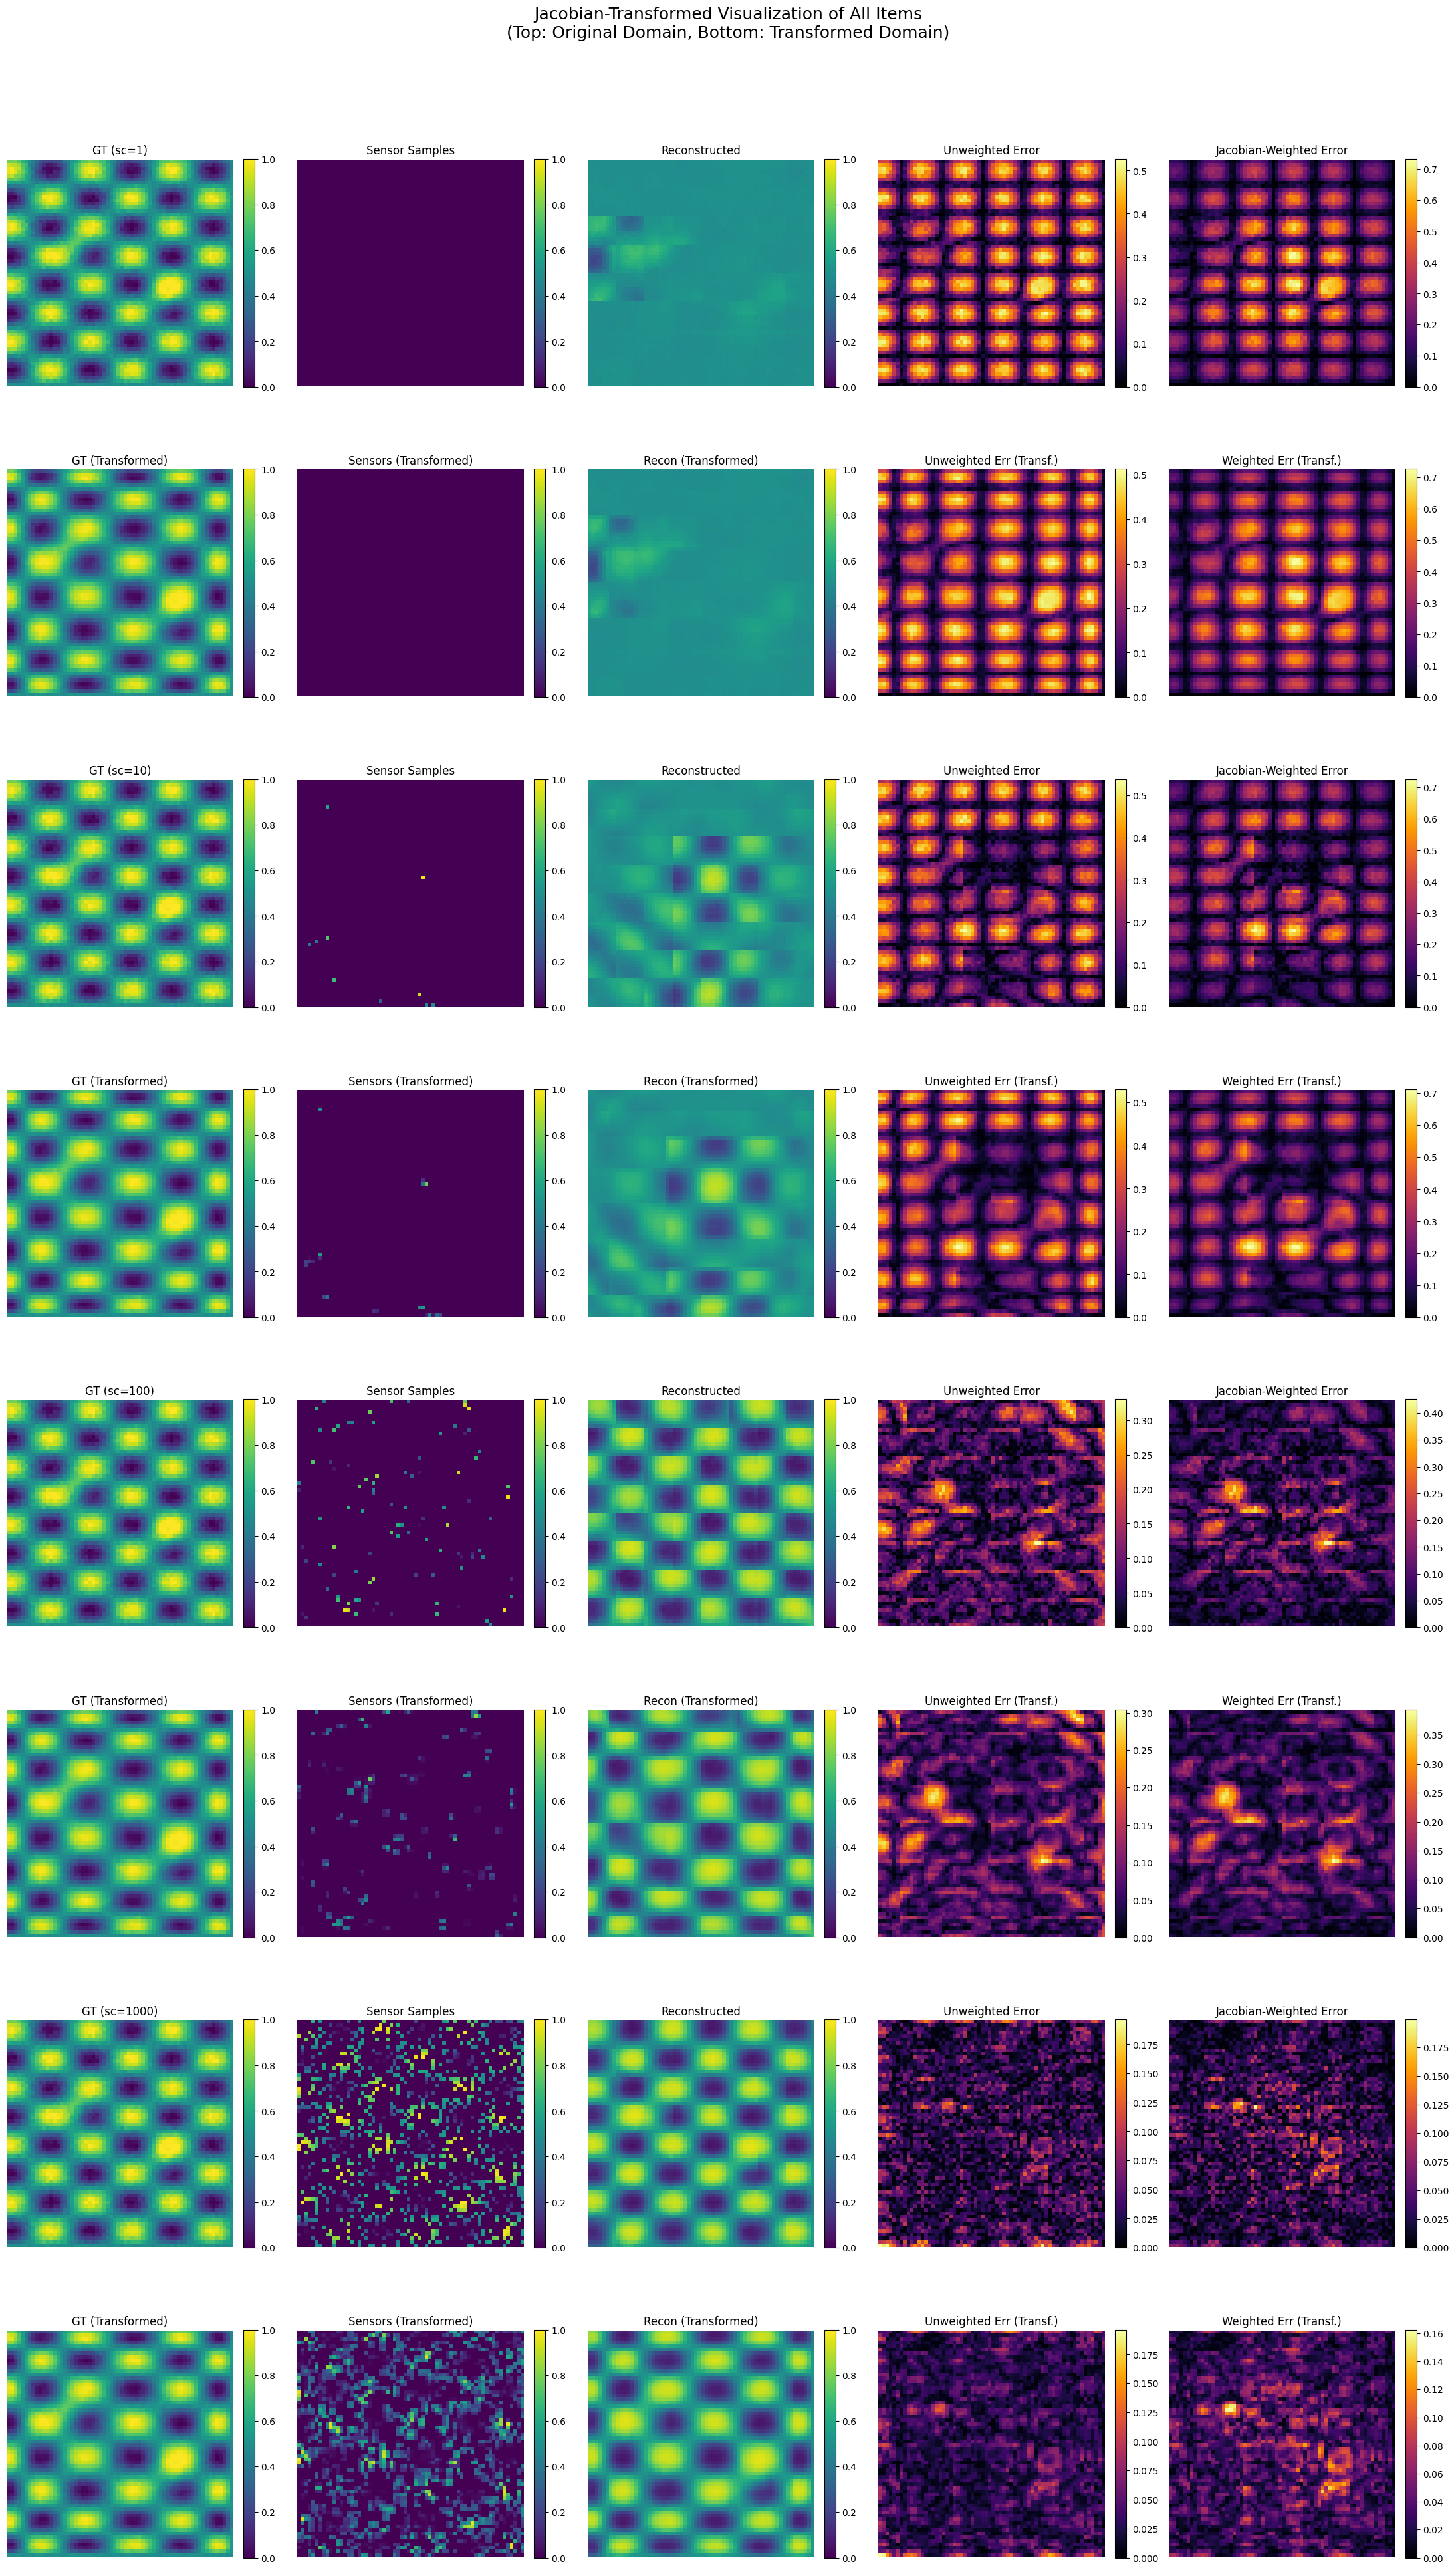

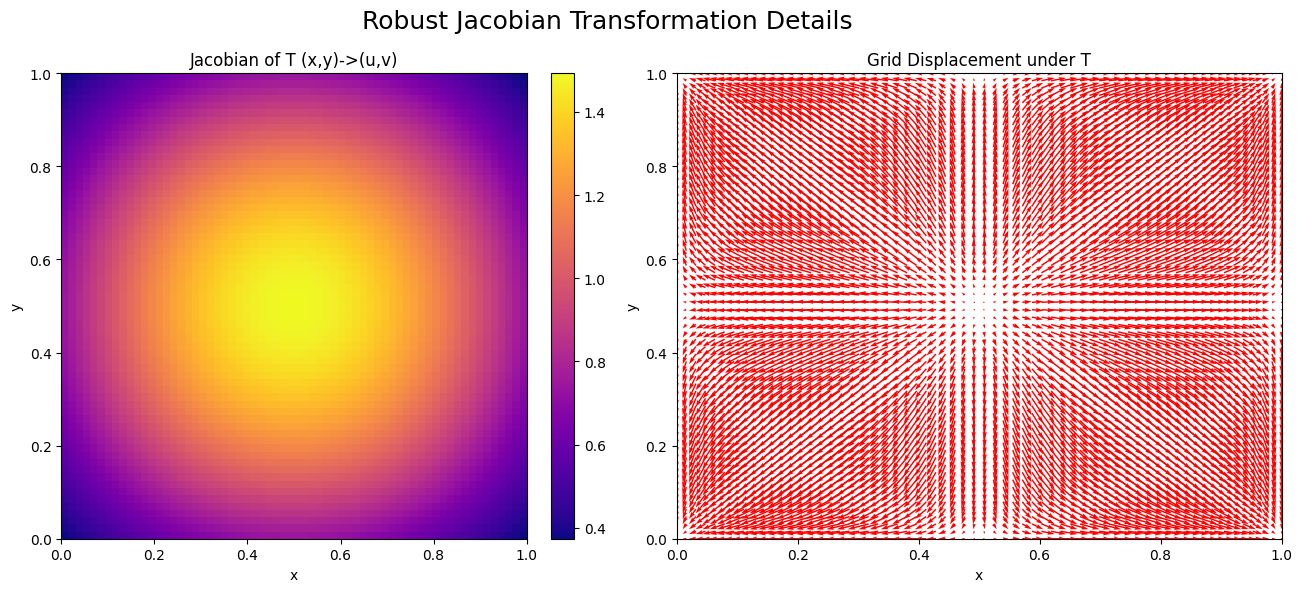

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

# For reproducibility
np.random.seed(42)
torch.manual_seed(42)

###############################################################################
# 1. Grid Definitions and Transformation
###############################################################################
grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

def T_grid(x, y):
    """
    The robust transformation T:
      u(x) = [x + (1 - cos(pi*x))/pi] / C,
      v(y) = [y + (1 - cos(pi*y))/pi] / C,
    with C = 1 + 2/pi.
    """
    C = 1 + 2/np.pi
    u = (x + (1 - np.cos(np.pi * x)) / np.pi) / C
    v = (y + (1 - np.cos(np.pi * y)) / np.pi) / C
    return u, v

def jacobian_T_robust(x, y):
    """
    J(x,y) = (1 + sin(pi*x))*(1 + sin(pi*y)) / (1 + 2/pi)^2
    """
    C = 1 + 2/np.pi
    du_dx = (1 + np.sin(np.pi * x)) / C
    dv_dy = (1 + np.sin(np.pi * y)) / C
    return du_dx * dv_dy

# Precompute the forward transformation and Jacobian on the entire grid.
u_grid, v_grid = T_grid(xx, yy)
J_grid = jacobian_T_robust(xx, yy)

###############################################################################
# 2. Warp Function: Map (x,y) domain images into (u,v) domain for visualization
###############################################################################
def warp_image(image_2d, xx, yy, u_grid, v_grid):
    """
    Warp a 2D image from (x,y)-space to (u,v)-space using griddata.
      image_2d: shape (64,64) in original domain
      (xx, yy): meshgrid of shape (64,64) for x,y in [0,1]
      (u_grid, v_grid): same shape (64,64), giving the mapped coords for each (x,y)
    Returns a new 64x64 image in (u,v)-space.
    """
    # Flatten original domain points and values
    points_xy = np.column_stack([u_grid.ravel(), v_grid.ravel()])
    values = image_2d.ravel()
    # Define a regular (u,v) grid from 0..1
    u_lin = np.linspace(0, 1, grid_size)
    v_lin = np.linspace(0, 1, grid_size)
    uu, vv = np.meshgrid(u_lin, v_lin)
    # Interpolate onto this uniform (u,v) grid
    warped = griddata(points_xy, values, (uu, vv), method='linear', fill_value=0.0)
    return np.clip(warped, 0, 1)  # or just warped if you prefer no clipping

###############################################################################
# 3. Random Sinusoidal Field Generator
###############################################################################
def generate_random_sinusoidal_field(add_hotspots=True):
    freq_x = np.random.uniform(2, 4)
    freq_y = np.random.uniform(2, 4)
    phase_x = np.random.uniform(0, 2*np.pi)
    phase_y = np.random.uniform(0, 2*np.pi)
    base = np.sin(2*np.pi*freq_x*xx + phase_x) * np.sin(2*np.pi*freq_y*yy + phase_y)
    base_norm = (base - base.min()) / (base.max()-base.min())
    field = base_norm.copy()
    if add_hotspots:
        hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
        for (cx, cy) in hotspot_centers:
            dist_sq = (xx - cx)**2 + (yy - cy)**2
            hotspot = np.exp(-dist_sq / 0.005)
            field += 0.3 * hotspot
        field = np.clip(field, 0, 1)
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0, 1)

###############################################################################
# 4. Dataset for Training
###############################################################################
class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [generate_random_sinusoidal_field() for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]  # shape: (64,64)
        total_points = grid_size * grid_size
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)
        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0
        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)
        inp = np.stack([masked_field, mask], axis=0)  # (2,64,64)
        tgt = field[np.newaxis, ...]                  # (1,64,64)
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

###############################################################################
# 5. Complex Autoencoder with LSTM+Attention
###############################################################################
class ComplexAutoencoder(nn.Module):
    def __init__(self):
        super(ComplexAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64->32
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32->16
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 16->8
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        self.attention = nn.MultiheadAttention(embed_dim=128, num_heads=4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),  # 8->16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),   # 16->32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),    # 32->64
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)             # (batch, 128, 8,8)
        bsz = encoded.shape[0]
        seq = encoded.view(bsz, 128, -1).permute(0, 2, 1)  # (bsz,64,128)
        lstm_out, _ = self.lstm(seq)         # (bsz,64,128)
        attn_input = lstm_out.permute(1, 0, 2) # (64, bsz,128)
        attn_output, _ = self.attention(attn_input, attn_input, attn_input)
        attn_out = attn_output + attn_input
        attn_out = attn_out.permute(1, 2, 0).contiguous().view(bsz, 128, 8, 8)
        out = self.decoder(attn_out)         # (bsz,1,64,64)
        return out

###############################################################################
# 6. Training Routine
###############################################################################
def train_autoencoder(sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    model = ComplexAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()

    # Evaluate MSE on test set
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

###############################################################################
# 7. Fixed Test Field, Fixed Sensor Masks, and Visualization
###############################################################################
# Create one fixed test field
test_field = generate_random_sinusoidal_field(add_hotspots=True)

def get_fixed_sample(field, sensor_count):
    np.random.seed(12345 + sensor_count)
    total_points = grid_size * grid_size
    sensor_indices = np.random.choice(total_points, sensor_count, replace=False)
    flat_field = field.flatten()
    flat_masked = np.zeros_like(flat_field, dtype=np.float32)
    flat_mask = np.zeros_like(flat_field, dtype=np.float32)
    flat_masked[sensor_indices] = flat_field[sensor_indices]
    flat_mask[sensor_indices] = 1.0
    masked_field = flat_masked.reshape(grid_size, grid_size)
    mask = flat_mask.reshape(grid_size, grid_size)
    inp = np.stack([masked_field, mask], axis=0)
    tgt = field[np.newaxis, ...]
    return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

sensor_counts = [1, 10, 100, 1000]

# We'll create a 2-row figure for each sensor count:
# Row 1: Original domain  (GT, Sensor, Recon, Unweighted Err, Weighted Err)
# Row 2: Transformed domain (the same five items after warping)
fig, axes = plt.subplots(len(sensor_counts)*2, 5, figsize=(22, 5*len(sensor_counts)*2))

row_index = 0
for sc in sensor_counts:
    # Train
    mse_val, model = train_autoencoder(sensor_count=sc, epochs=40, batch_size=32)
    print(f"Sensor count {sc}, Test MSE on random fields: {mse_val:.4f}")

    # Evaluate on fixed test field
    inp, tgt = get_fixed_sample(test_field, sc)
    model.eval()
    with torch.no_grad():
        pred = model(inp.unsqueeze(0)).squeeze(0).squeeze(0).numpy()

    gt = tgt.squeeze(0).numpy()
    sensor_samples = inp[0].numpy()

    # Compute errors
    abs_error = np.abs(gt - pred)
    weighted_error = abs_error * J_grid
    robust_mse = np.mean(weighted_error)
    print(f"  -> On fixed field, Jacobian-weighted MSE: {robust_mse:.4f}")

    # =========================== ORIGINAL DOMAIN PLOTS =======================
    # GT
    ax = axes[row_index, 0]
    im = ax.imshow(gt, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(f"GT (sc={sc})")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Sensor
    ax = axes[row_index, 1]
    im = ax.imshow(sensor_samples, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Sensor Samples")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Reconstruction
    ax = axes[row_index, 2]
    im = ax.imshow(pred, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Reconstructed")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Unweighted Error
    ax = axes[row_index, 3]
    im = ax.imshow(abs_error, cmap='inferno', vmin=0, vmax=abs_error.max())
    ax.set_title("Unweighted Error")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Weighted Error
    ax = axes[row_index, 4]
    im = ax.imshow(weighted_error, cmap='inferno', vmin=0, vmax=weighted_error.max())
    ax.set_title("Jacobian-Weighted Error")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # ========================= TRANSFORMED DOMAIN PLOTS =====================
    row_index_transformed = row_index + 1

    # Warp each item into (u,v)-space
    gt_warped           = warp_image(gt, xx, yy, u_grid, v_grid)
    sensor_warped       = warp_image(sensor_samples, xx, yy, u_grid, v_grid)
    pred_warped         = warp_image(pred, xx, yy, u_grid, v_grid)
    abs_error_warped    = warp_image(abs_error, xx, yy, u_grid, v_grid)
    weighted_error_warp = warp_image(weighted_error, xx, yy, u_grid, v_grid)

    # GT
    ax = axes[row_index_transformed, 0]
    im = ax.imshow(gt_warped, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("GT (Transformed)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Sensor
    ax = axes[row_index_transformed, 1]
    im = ax.imshow(sensor_warped, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Sensors (Transformed)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Reconstruction
    ax = axes[row_index_transformed, 2]
    im = ax.imshow(pred_warped, cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Recon (Transformed)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Unweighted Error
    ax = axes[row_index_transformed, 3]
    im = ax.imshow(abs_error_warped, cmap='inferno', vmin=0, vmax=abs_error_warped.max())
    ax.set_title("Unweighted Err (Transf.)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Weighted Error
    ax = axes[row_index_transformed, 4]
    im = ax.imshow(weighted_error_warp, cmap='inferno',
                   vmin=0, vmax=weighted_error_warp.max())
    ax.set_title("Weighted Err (Transf.)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    row_index += 2  # move to the next 2-row block

plt.suptitle("Jacobian-Transformed Visualization of All Items\n(Top: Original Domain, Bottom: Transformed Domain)",
             fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

###############################################################################
# 8. Additional Visualization of the Transformation
###############################################################################
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
# Left: Jacobian map
im1 = axs[0].imshow(J_grid, cmap='plasma', extent=(0,1,0,1), origin='lower')
axs[0].set_title("Jacobian of T (x,y)->(u,v)")
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
fig.colorbar(im1, ax=axs[0], fraction=0.046, pad=0.04)

# Right: Quiver of displacement
dx = u_grid - xx
dy = v_grid - yy
axs[1].quiver(xx, yy, dx, dy, angles='xy', scale_units='xy', scale=1, color='red')
axs[1].set_title("Grid Displacement under T")
axs[1].set_xlabel("x")
axs[1].set_ylabel("y")
axs[1].set_xlim(0,1)
axs[1].set_ylim(0,1)
plt.suptitle("Robust Jacobian Transformation Details", fontsize=18)
plt.tight_layout()
plt.show()

Sensor count 1, Test MSE on random fields: 0.0619
  -> On fixed field, Jacobian-weighted MSE: 0.1991
Sensor count 10, Test MSE on random fields: 0.0497
  -> On fixed field, Jacobian-weighted MSE: 0.1614
Sensor count 100, Test MSE on random fields: 0.0109
  -> On fixed field, Jacobian-weighted MSE: 0.0748
Sensor count 1000, Test MSE on random fields: 0.0015
  -> On fixed field, Jacobian-weighted MSE: 0.0318


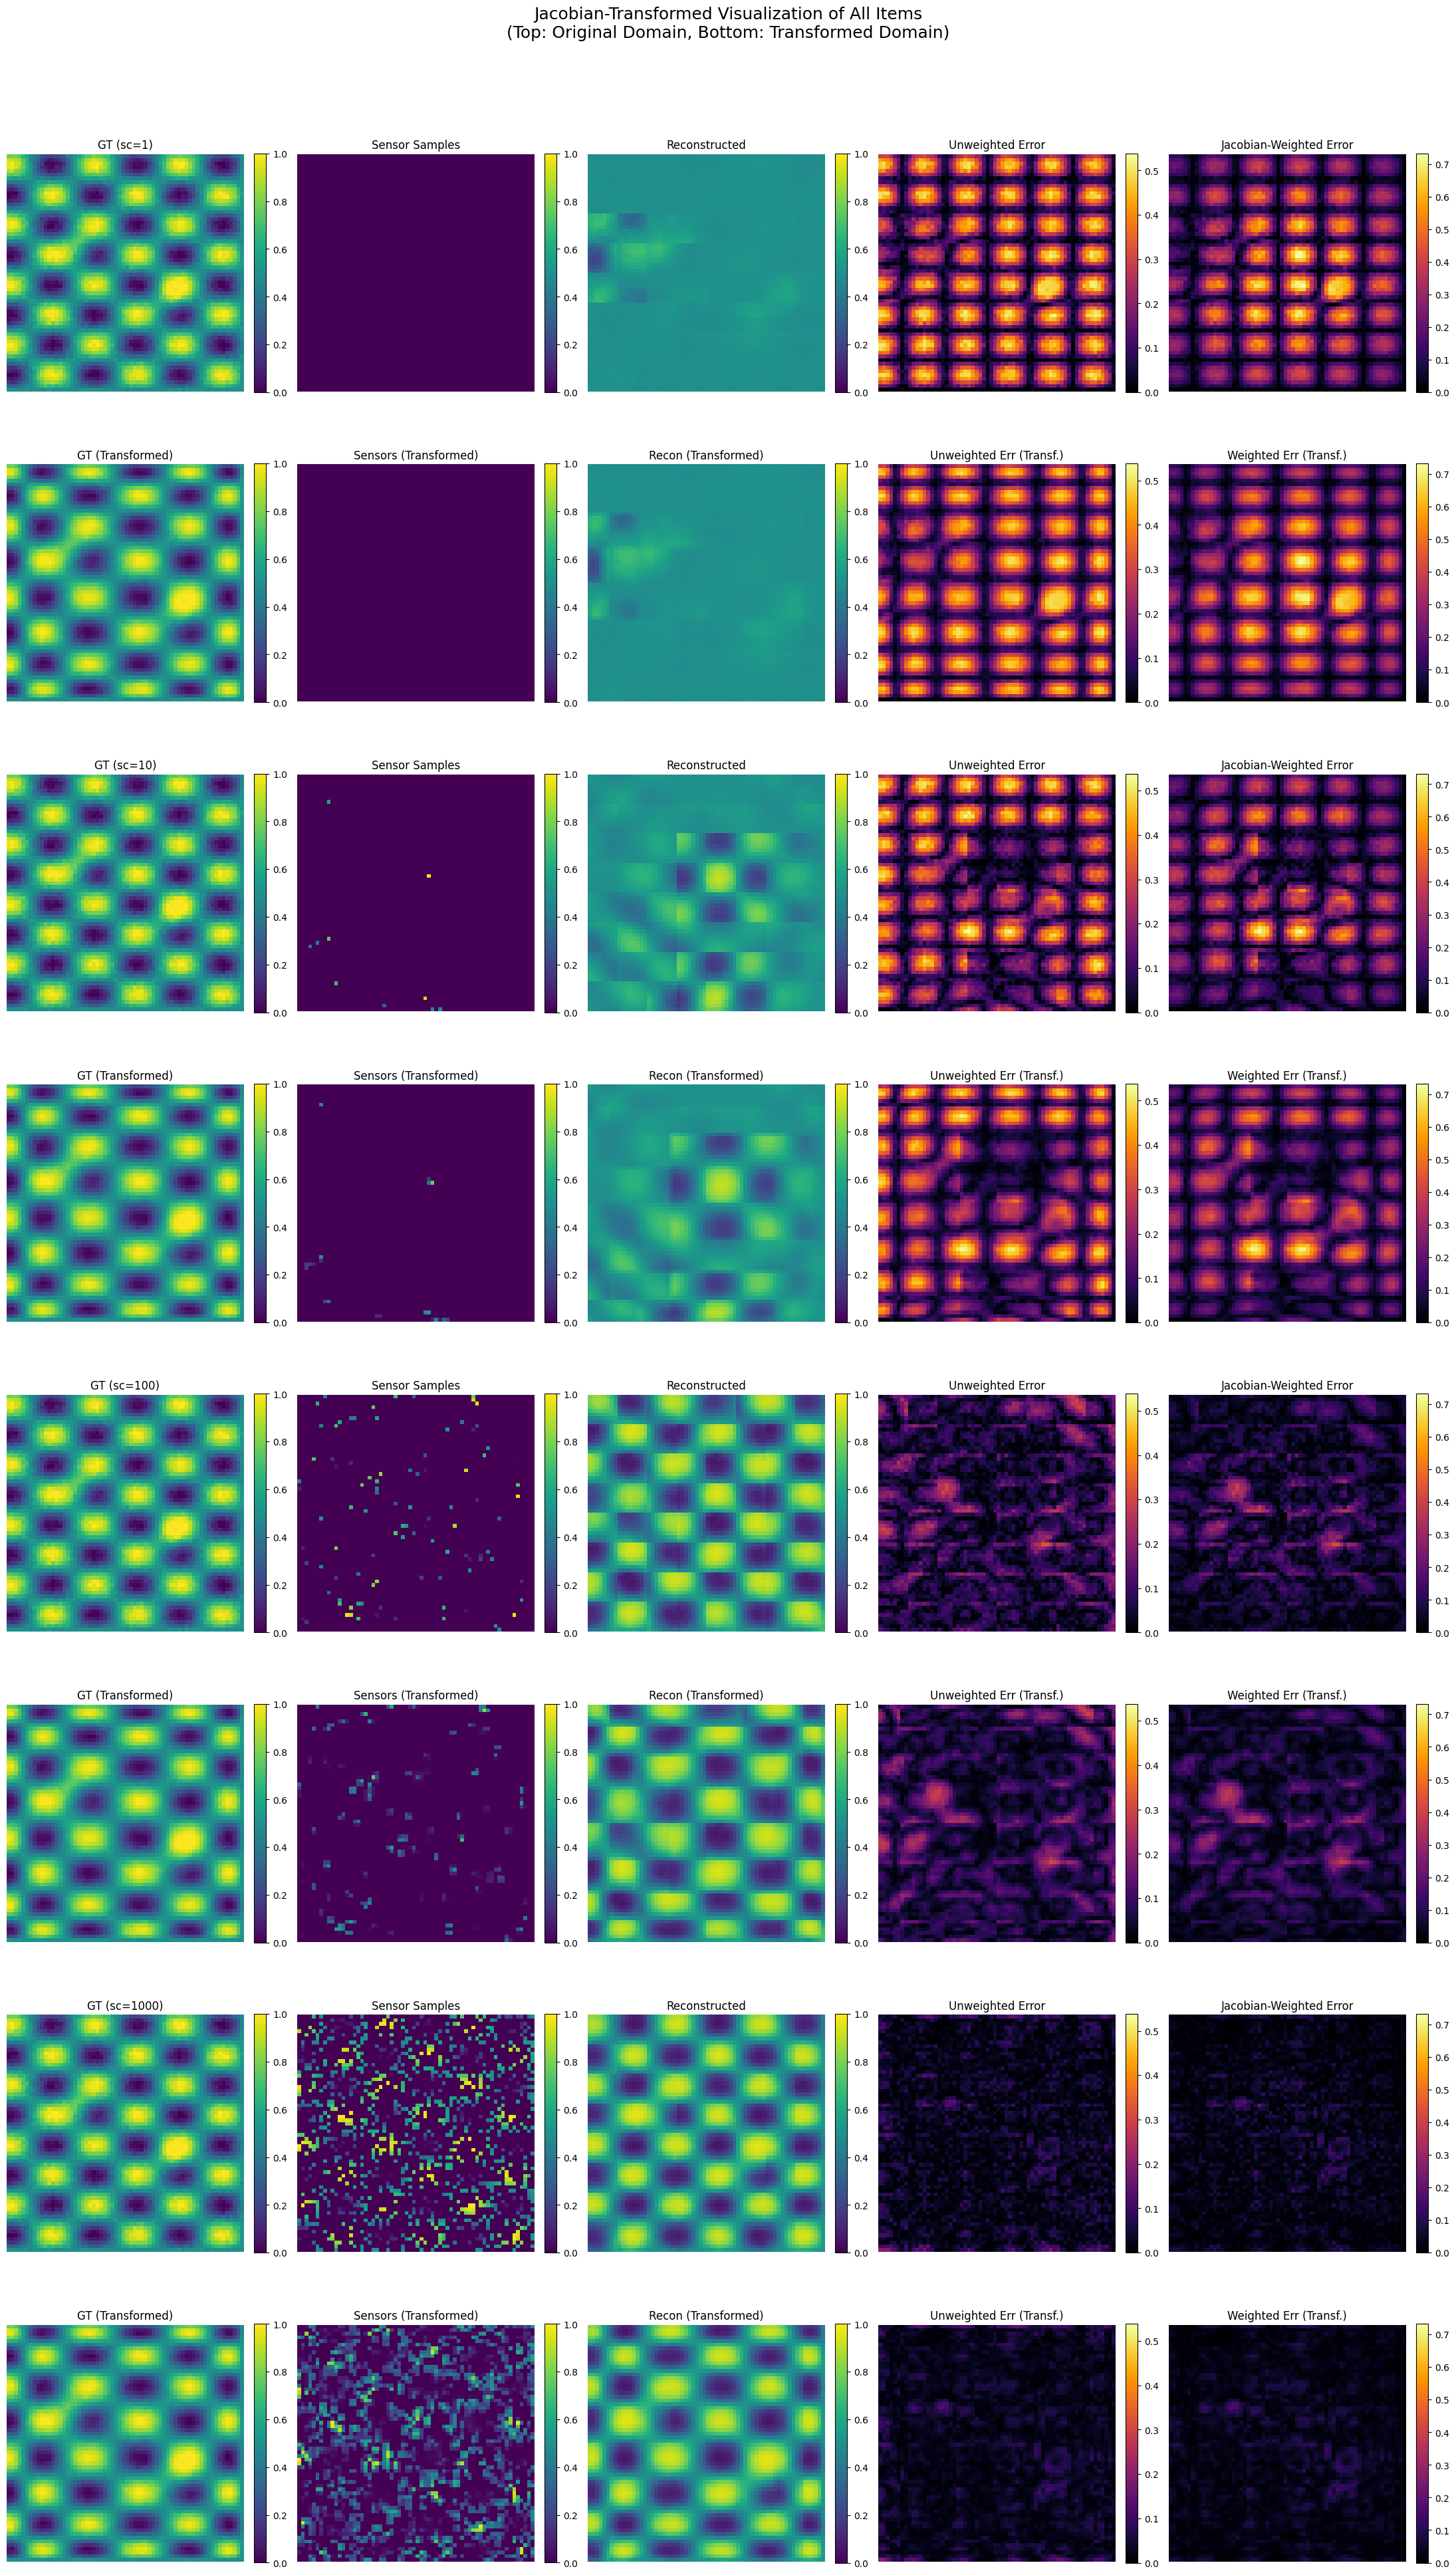

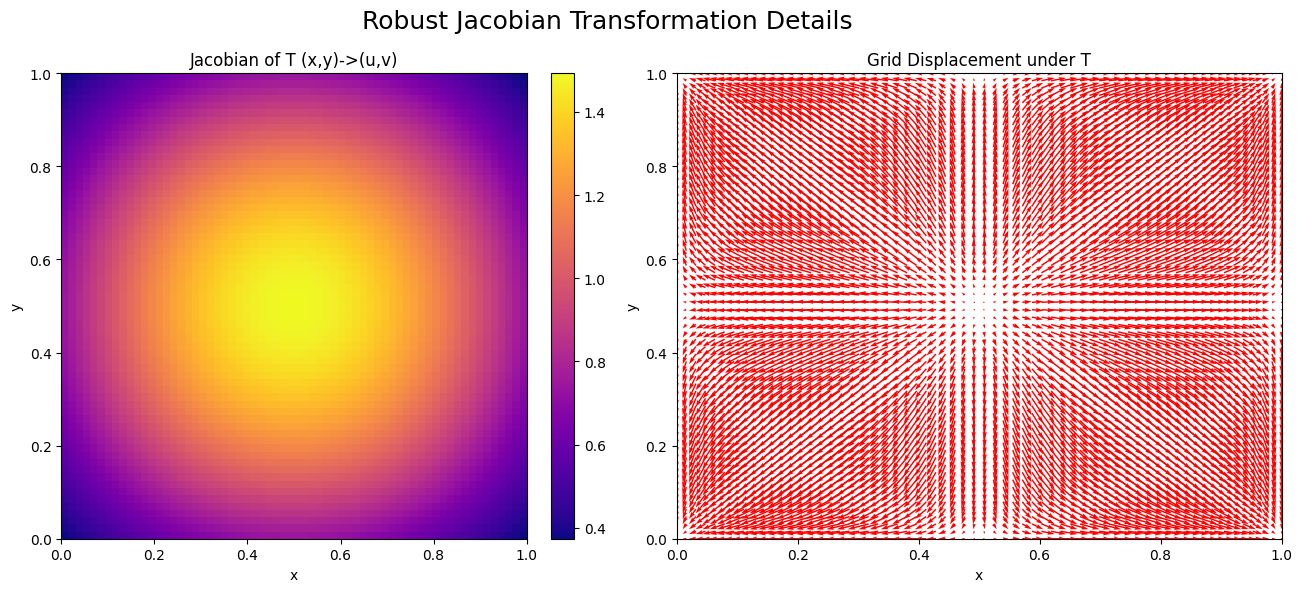

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

np.random.seed(42)
torch.manual_seed(42)

grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

def T_grid(x, y):
    C = 1 + 2/np.pi
    u = (x + (1 - np.cos(np.pi * x)) / np.pi) / C
    v = (y + (1 - np.cos(np.pi * y)) / np.pi) / C
    return u, v

def jacobian_T_robust(x, y):
    C = 1 + 2/np.pi
    du_dx = (1 + np.sin(np.pi * x)) / C
    dv_dy = (1 + np.sin(np.pi * y)) / C
    return du_dx * dv_dy

u_grid, v_grid = T_grid(xx, yy)
J_grid = jacobian_T_robust(xx, yy)

def warp_image(image_2d, xx, yy, u_grid, v_grid):
    points_xy = np.column_stack([u_grid.ravel(), v_grid.ravel()])
    values = image_2d.ravel()
    u_lin = np.linspace(0, 1, grid_size)
    v_lin = np.linspace(0, 1, grid_size)
    uu, vv = np.meshgrid(u_lin, v_lin)
    warped = griddata(points_xy, values, (uu, vv), method='linear', fill_value=0.0)
    return np.clip(warped, 0, 1)

def generate_random_sinusoidal_field(add_hotspots=True):
    freq_x = np.random.uniform(2, 4)
    freq_y = np.random.uniform(2, 4)
    phase_x = np.random.uniform(0, 2*np.pi)
    phase_y = np.random.uniform(0, 2*np.pi)
    base = np.sin(2*np.pi*freq_x*xx + phase_x) * np.sin(2*np.pi*freq_y*yy + phase_y)
    base_norm = (base - base.min()) / (base.max()-base.min())
    field = base_norm.copy()
    if add_hotspots:
        hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
        for (cx, cy) in hotspot_centers:
            dist_sq = (xx - cx)**2 + (yy - cy)**2
            hotspot = np.exp(-dist_sq / 0.005)
            field += 0.3 * hotspot
        field = np.clip(field, 0, 1)
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0, 1)

class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [generate_random_sinusoidal_field() for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]
        total_points = grid_size * grid_size
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)
        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0
        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)
        inp = np.stack([masked_field, mask], axis=0)
        tgt = field[np.newaxis, ...]
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

class ComplexAutoencoder(nn.Module):
    def __init__(self):
        super(ComplexAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        self.attention = nn.MultiheadAttention(embed_dim=128, num_heads=4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        bsz = encoded.shape[0]
        seq = encoded.view(bsz, 128, -1).permute(0, 2, 1)
        lstm_out, _ = self.lstm(seq)
        attn_input = lstm_out.permute(1, 0, 2)
        attn_output, _ = self.attention(attn_input, attn_input, attn_input)
        attn_out = attn_output + attn_input
        attn_out = attn_out.permute(1, 2, 0).contiguous().view(bsz, 128, 8, 8)
        out = self.decoder(attn_out)
        return out

def train_autoencoder(sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    model = ComplexAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

def get_fixed_sample(field, sensor_count):
    np.random.seed(12345 + sensor_count)
    total_points = grid_size * grid_size
    sensor_indices = np.random.choice(total_points, sensor_count, replace=False)
    flat_field = field.flatten()
    flat_masked = np.zeros_like(flat_field, dtype=np.float32)
    flat_mask = np.zeros_like(flat_field, dtype=np.float32)
    flat_masked[sensor_indices] = flat_field[sensor_indices]
    flat_mask[sensor_indices] = 1.0
    masked_field = flat_masked.reshape(grid_size, grid_size)
    mask = flat_mask.reshape(grid_size, grid_size)
    inp = np.stack([masked_field, mask], axis=0)
    tgt = field[np.newaxis, ...]
    return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

test_field = generate_random_sinusoidal_field(add_hotspots=True)
sensor_counts = [1, 10, 100, 1000]
results = []

global_unweighted_max = 0
global_weighted_max = 0

for sc in sensor_counts:
    mse_val, model = train_autoencoder(sensor_count=sc, epochs=40, batch_size=32)
    print(f"Sensor count {sc}, Test MSE on random fields: {mse_val:.4f}")
    inp, tgt = get_fixed_sample(test_field, sc)
    model.eval()
    with torch.no_grad():
        pred = model(inp.unsqueeze(0)).squeeze(0).squeeze(0).numpy()
    gt = tgt.squeeze(0).numpy()
    sensor_samples = inp[0].numpy()
    abs_error = np.abs(gt - pred)
    weighted_error = abs_error * J_grid
    robust_mse = np.mean(weighted_error)
    print(f"  -> On fixed field, Jacobian-weighted MSE: {robust_mse:.4f}")
    abs_error_warped = warp_image(abs_error, xx, yy, u_grid, v_grid)
    weighted_error_warp = warp_image(weighted_error, xx, yy, u_grid, v_grid)
    max_unweighted = max(abs_error.max(), abs_error_warped.max())
    max_weighted = max(weighted_error.max(), weighted_error_warp.max())
    if max_unweighted > global_unweighted_max:
        global_unweighted_max = max_unweighted
    if max_weighted > global_weighted_max:
        global_weighted_max = max_weighted
    results.append({
        'sc': sc,
        'gt': gt,
        'sensor_samples': sensor_samples,
        'pred': pred,
        'abs_error': abs_error,
        'weighted_error': weighted_error,
        'gt_warped': warp_image(gt, xx, yy, u_grid, v_grid),
        'sensor_warped': warp_image(sensor_samples, xx, yy, u_grid, v_grid),
        'pred_warped': warp_image(pred, xx, yy, u_grid, v_grid),
        'abs_error_warped': abs_error_warped,
        'weighted_error_warp': weighted_error_warp
    })

fig, axes = plt.subplots(len(sensor_counts)*2, 5, figsize=(22, 5*len(sensor_counts)*2))
row_index = 0

for res in results:
    sc = res['sc']
    ax = axes[row_index, 0]
    im = ax.imshow(res['gt'], cmap='viridis', vmin=0, vmax=1)
    ax.set_title(f"GT (sc={sc})")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index, 1]
    im = ax.imshow(res['sensor_samples'], cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Sensor Samples")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index, 2]
    im = ax.imshow(res['pred'], cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Reconstructed")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index, 3]
    im = ax.imshow(res['abs_error'], cmap='inferno', vmin=0, vmax=global_unweighted_max)
    ax.set_title("Unweighted Error")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index, 4]
    im = ax.imshow(res['weighted_error'], cmap='inferno', vmin=0, vmax=global_weighted_max)
    ax.set_title("Jacobian-Weighted Error")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    row_index_transformed = row_index + 1
    ax = axes[row_index_transformed, 0]
    im = ax.imshow(res['gt_warped'], cmap='viridis', vmin=0, vmax=1)
    ax.set_title("GT (Transformed)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index_transformed, 1]
    im = ax.imshow(res['sensor_warped'], cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Sensors (Transformed)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index_transformed, 2]
    im = ax.imshow(res['pred_warped'], cmap='viridis', vmin=0, vmax=1)
    ax.set_title("Recon (Transformed)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index_transformed, 3]
    im = ax.imshow(res['abs_error_warped'], cmap='inferno', vmin=0, vmax=global_unweighted_max)
    ax.set_title("Unweighted Err (Transf.)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    ax = axes[row_index_transformed, 4]
    im = ax.imshow(res['weighted_error_warp'], cmap='inferno', vmin=0, vmax=global_weighted_max)
    ax.set_title("Weighted Err (Transf.)")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    row_index += 2

plt.suptitle("Jacobian-Transformed Visualization of All Items\n(Top: Original Domain, Bottom: Transformed Domain)", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
im1 = axs[0].imshow(J_grid, cmap='plasma', extent=(0,1,0,1), origin='lower')
axs[0].set_title("Jacobian of T (x,y)->(u,v)")
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
fig.colorbar(im1, ax=axs[0], fraction=0.046, pad=0.04)
dx = u_grid - xx
dy = v_grid - yy
axs[1].quiver(xx, yy, dx, dy, angles='xy', scale_units='xy', scale=1, color='red')
axs[1].set_title("Grid Displacement under T")
axs[1].set_xlabel("x")
axs[1].set_ylabel("y")
axs[1].set_xlim(0,1)
axs[1].set_ylim(0,1)
plt.suptitle("Robust Jacobian Transformation Details", fontsize=18)
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

np.random.seed(42)
torch.manual_seed(42)

grid_size = 64
x_vals = np.linspace(0, 1, grid_size)
y_vals = np.linspace(0, 1, grid_size)
xx, yy = np.meshgrid(x_vals, y_vals)

def T_grid(x, y):
    C = 1 + 2/np.pi
    u = (x + (1 - np.cos(np.pi * x)) / np.pi) / C
    v = (y + (1 - np.cos(np.pi * y)) / np.pi) / C
    return u, v

def jacobian_T_robust(x, y):
    C = 1 + 2/np.pi
    du_dx = (1 + np.sin(np.pi * x)) / C
    dv_dy = (1 + np.sin(np.pi * y)) / C
    return du_dx * dv_dy

u_grid, v_grid = T_grid(xx, yy)
J_grid = jacobian_T_robust(xx, yy)

def warp_image(image_2d, xx, yy, u_grid, v_grid):
    points_xy = np.column_stack([u_grid.ravel(), v_grid.ravel()])
    values = image_2d.ravel()
    u_lin = np.linspace(0, 1, grid_size)
    v_lin = np.linspace(0, 1, grid_size)
    uu, vv = np.meshgrid(u_lin, v_lin)
    warped = griddata(points_xy, values, (uu, vv), method='linear', fill_value=0.0)
    return np.clip(warped, 0, 1)

def generate_random_sinusoidal_field(add_hotspots=True):
    freq_x = np.random.uniform(2, 4)
    freq_y = np.random.uniform(2, 4)
    phase_x = np.random.uniform(0, 2*np.pi)
    phase_y = np.random.uniform(0, 2*np.pi)
    base = np.sin(2*np.pi*freq_x*xx + phase_x) * np.sin(2*np.pi*freq_y*yy + phase_y)
    base_norm = (base - base.min()) / (base.max()-base.min())
    field = base_norm.copy()
    if add_hotspots:
        hotspot_centers = [(0.3, 0.4), (0.7, 0.6)]
        for (cx, cy) in hotspot_centers:
            dist_sq = (xx - cx)**2 + (yy - cy)**2
            hotspot = np.exp(-dist_sq / 0.005)
            field += 0.3 * hotspot
        field = np.clip(field, 0, 1)
    noise = np.random.normal(0, 0.02, size=field.shape)
    return np.clip(field + noise, 0, 1)

class SensorFieldDataset(Dataset):
    def __init__(self, num_samples, sensor_count):
        self.num_samples = num_samples
        self.sensor_count = sensor_count
        self.fields = [generate_random_sinusoidal_field() for _ in range(num_samples)]

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        field = self.fields[idx]
        total_points = grid_size * grid_size
        sensor_indices = np.random.choice(total_points, self.sensor_count, replace=False)
        flat_field = field.flatten()
        flat_masked = np.zeros_like(flat_field, dtype=np.float32)
        flat_mask = np.zeros_like(flat_field, dtype=np.float32)
        flat_masked[sensor_indices] = flat_field[sensor_indices]
        flat_mask[sensor_indices] = 1.0
        masked_field = flat_masked.reshape(grid_size, grid_size)
        mask = flat_mask.reshape(grid_size, grid_size)
        inp = np.stack([masked_field, mask], axis=0)
        tgt = field[np.newaxis, ...]
        return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

class ComplexAutoencoder(nn.Module):
    def __init__(self):
        super(ComplexAutoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        self.attention = nn.MultiheadAttention(embed_dim=128, num_heads=4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        bsz = encoded.shape[0]
        seq = encoded.view(bsz, 128, -1).permute(0, 2, 1)
        lstm_out, _ = self.lstm(seq)
        attn_input = lstm_out.permute(1, 0, 2)
        attn_output, _ = self.attention(attn_input, attn_input, attn_input)
        attn_out = attn_output + attn_input
        attn_out = attn_out.permute(1, 2, 0).contiguous().view(bsz, 128, 8, 8)
        out = self.decoder(attn_out)
        return out

def train_autoencoder(sensor_count, epochs=40, batch_size=32):
    train_dataset = SensorFieldDataset(num_samples=400, sensor_count=sensor_count)
    test_dataset  = SensorFieldDataset(num_samples=100, sensor_count=sensor_count)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    model = ComplexAutoencoder()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()
    model.train()
    for _ in range(epochs):
        for inp, tgt in train_loader:
            optimizer.zero_grad()
            pred = model(inp)
            loss = criterion(pred, tgt)
            loss.backward()
            optimizer.step()
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for inp, tgt in test_loader:
            pred = model(inp)
            loss = criterion(pred, tgt)
            total_loss += loss.item() * inp.size(0)
    mse = total_loss / len(test_dataset)
    return mse, model

def get_fixed_sample(field, sensor_count):
    np.random.seed(12345 + sensor_count)
    total_points = grid_size * grid_size
    sensor_indices = np.random.choice(total_points, sensor_count, replace=False)
    flat_field = field.flatten()
    flat_masked = np.zeros_like(flat_field, dtype=np.float32)
    flat_mask = np.zeros_like(flat_field, dtype=np.float32)
    flat_masked[sensor_indices] = flat_field[sensor_indices]
    flat_mask[sensor_indices] = 1.0
    masked_field = flat_masked.reshape(grid_size, grid_size)
    mask = flat_mask.reshape(grid_size, grid_size)
    inp = np.stack([masked_field, mask], axis=0)
    tgt = field[np.newaxis, ...]
    return torch.tensor(inp, dtype=torch.float32), torch.tensor(tgt, dtype=torch.float32)

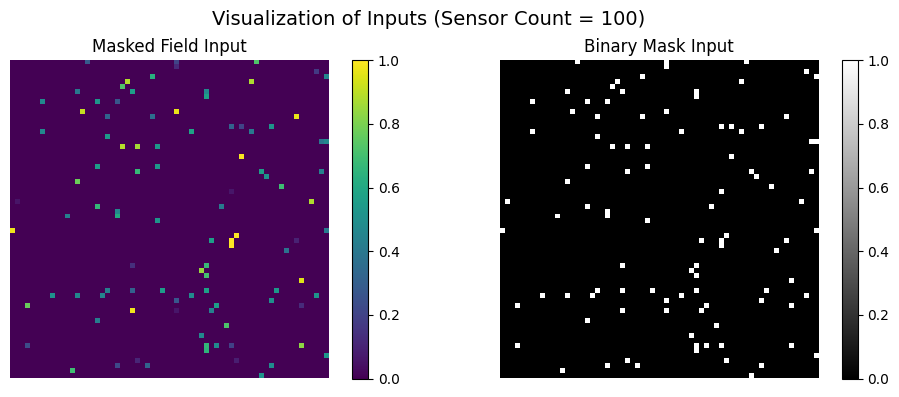

In [ ]:
import matplotlib.pyplot as plt

# Generate one sample from the dataset
sensor_count = 100  # You can change this
dataset = SensorFieldDataset(num_samples=1, sensor_count=sensor_count)
(inp, tgt) = dataset[0]  # Shape of inp: [2, 64, 64]

# Extract the two input channels
masked_field = inp[0].numpy()  # sensor values, 0 elsewhere
binary_mask  = inp[1].numpy()  # 1 where sensors are placed

# Plot the two inputs
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(masked_field, cmap='viridis', vmin=0, vmax=1)
plt.title("Masked Field Input")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_mask, cmap='gray', vmin=0, vmax=1)
plt.title("Binary Mask Input")
plt.colorbar()
plt.axis("off")

plt.suptitle(f"Visualization of Inputs (Sensor Count = {sensor_count})", fontsize=14)
plt.tight_layout()
plt.show()